# Emotion Detection from Text — Deep Learning & Transformers
### Project 2 · Kaggle "Emotions Dataset for NLP" (6 classes: anger, fear, joy, love, sadness, surprise)

**Goal.** Re-approach the emotion-detection problem from Project 1 (classical ML, best model: Linear SVM + TF-IDF, test macro-F1 = 0.8613) using **sequence models built in Keras** and **pretrained transformers**, then decide which model is best.

**Result, up front.** 21 models were trained and compared on an identical train/val/test split with macro-F1 as the primary metric. The three fine-tuned transformers (RoBERTa, BERT, DistilBERT) all beat every RNN on validation macro-F1 and are the only models that are a clean "good fit" (no overfitting). Under the pre-declared selection rule (highest validation F1, then smallest/fastest among near-ties), **DistilBERT is the recommended model** — it also happens to have the best test macro-F1 (0.897) and test accuracy (93.0%) of all 21 models, at less than half the size of BERT. A tuned RNN (LSTM stacked) is close behind on test and is a much cheaper CPU-only alternative. Full detail is in the comparison table and discussion near the end of this notebook.

**Two notebooks, one project.** This machine has no NVIDIA GPU, so the pipeline is split across two files that share the same data, splits, labels and class weights:
- **This notebook** (run locally, CPU): data loading, EDA, cleaning, all 9 RNN architectures, KerasTuner, and the final joined comparison/analysis.
- **`Emotions_RNN_Colab.ipynb`** (run on a Colab T4 GPU): fine-tuning BERT, DistilBERT and RoBERTa. Its results (`transformer_results.csv`, `transformer_artifacts.pkl`) are downloaded and read back in here, in the "Final Comparison" section.

**How this notebook maps to the assignment**

| Requirement | Where |
|---|---|
| i. Download & load the dataset | Load the Dataset |
| ii. Cleaning (lowercase, stopwords, stemming, lemmatization) | Text Cleaning |
| iii. Simple RNN / LSTM / GRU, Bidirectional, Stacked | Section 6 |
| iv. Hyperparameter tuning with KerasTuner | Section 7 |
| v. Pretrained BERT, DistilBERT, RoBERTa | `Emotions_RNN_Colab.ipynb` (joined back in Section 9) |
| vi. Overfitting / underfitting check | Section 10 |
| vii. Comparison table & best-model recommendation | Section 9 |

**Methodology carried over from Project 1** (so the two projects are comparable):
- Same data, same splits, same cleaning pipeline (lemmatization chosen over stemming).
- **Macro-F1** is the primary metric (classes are imbalanced: joy ≈ 34%, surprise ≈ 3.6%); accuracy is reported as a secondary metric.
- `class_weight="balanced"` equivalent is used for every neural model.
- Everything that "learns" (vocabulary, class weights, tokenizer) is fit on **train only**. Validation is used for early stopping/tuning/model selection; the **test set is used only for final reporting**.

**Two deliberate differences from Project 1**
1. The RNNs in this notebook use the *cleaned* text, same as Project 1. **The transformers (other notebook) use the *raw* text** — they were pretrained on natural sentences with their own sub-word tokenizer, and stopwords/negations carry information they can use. Cleaning them would hurt, not help.
2. Word order matters now. Project 1's TF-IDF/Bag-of-Words ignored order; RNNs and transformers do not.

## Setup

**Why:** install the extra libraries (KerasTuner, Hugging Face), fix random seeds for reproducibility, and centralise all "knobs" (epochs, number of tuner trials) in one place so the notebook is easy to re-run at a different scale.

**Design choice — two frameworks.** Keras/TensorFlow is used for the RNN family (as the assignment specifies KerasTuner). The transformers are fine-tuned with Hugging Face + PyTorch, which is the best-supported path and avoids Keras-3/TF-transformers compatibility problems.

In [1]:
import os, re, glob, time, gc, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import kagglehub

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

import tensorflow as tf
import keras
from keras import layers
import keras_tuner as kt

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---------------- configuration ----------------
SEED = 42
QUICK_TEST = False          # True = tiny run (small data, 1-2 epochs) just to check the notebook works end-to-end

BASELINE_EPOCHS    = 20     # max epochs for baseline RNN models (early stopping will usually cut this short)
TUNER_TRIALS       = 6      # hyperparameter combinations tried per architecture
TUNER_EPOCHS       = 12     # max epochs per tuner trial
FINAL_EPOCHS       = 30     # max epochs when re-training each tuned model
TRANSFORMER_EPOCHS = 4
BATCH_SIZE         = 64

if QUICK_TEST:
    BASELINE_EPOCHS = TUNER_EPOCHS = FINAL_EPOCHS = 2
    TUNER_TRIALS, TRANSFORMER_EPOCHS = 2, 1

random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)


d:\Data Science\Deployments\RNN_NLP - Emoticons\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow 2.21.0 | Keras 3.15.1


## Load the Dataset 

**Why:** the dataset ships as three semicolon-separated text files (`sentence;emotion`, no header): `train.txt` (16,000), `val.txt` (2,000), `test.txt` (2,000). We keep the official split so results are directly comparable with Project 1.

**How:** `kagglehub` downloads the dataset straight into a local `emotions/` folder (`output_dir="emotions"`), so it sits next to this notebook rather than in the global cache.

In [2]:
path = kagglehub.dataset_download("praveengovi/emotions-dataset-for-nlp", output_dir="emotions")

100%|██████████| 721k/721k [00:01<00:00, 497kB/s]

Extracting files...


In [3]:
train_df = pd.read_csv("emotions/train.txt", sep=";", header=None, names=["text", "emotion"])
val_df   = pd.read_csv("emotions/val.txt",   sep=";", header=None, names=["text", "emotion"])
test_df  = pd.read_csv("emotions/test.txt",  sep=";", header=None, names=["text", "emotion"])

print(train_df.shape, val_df.shape, test_df.shape)
train_df.head()

(16000, 2) (2000, 2) (2000, 2)


,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


**Interpretation.** You should see 16 000 / 2 000 / 2 000 rows and two columns. Each sentence is a short, first-person statement, typically of the form *"i feel …"* — this structural regularity is a property of how the data was collected and is the main reason a 90 % accuracy is reachable even with simple models (see Limitations).

##  Data Quality Check & Quick EDA

**Why:** before modelling we must confirm there are no nulls/duplicates, understand class imbalance (it decides the metric and whether we need class weights) and check text length (it decides the padded sequence length for RNNs). Project 1 already did the full EDA, so this section is a compact re-check.

In [4]:
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{n:5s} shape={d.shape}  nulls={int(d.isna().sum().sum())}  duplicates={int(d.duplicated().sum())}")


train shape=(16000, 2)  nulls=0  duplicates=1
val   shape=(2000, 2)  nulls=0  duplicates=0
test  shape=(2000, 2)  nulls=0  duplicates=0


**Interpretation.** Train has exactly **1 duplicate row** and no nulls; val and test have neither. This matches Project 1, and confirms the data is clean apart from that single repeated sentence, which we drop from train only (val/test must stay exactly as published, since they are the evaluation set).

In [5]:
# drop duplicates from TRAIN only (as in Project 1); val/test stay untouched so the evaluation set is identical
train_df = train_df.drop_duplicates().reset_index(drop=True)

In [6]:
# leakage check: identical sentences appearing in more than one split
print("train & val identical sentences :", len(set(train_df.text) & set(val_df.text)))
print("train & test identical sentences:", len(set(train_df.text) & set(test_df.text)))

if QUICK_TEST:   # tiny subset for the smoke test
    train_df = train_df.sample(min(2000, len(train_df)), random_state=SEED).reset_index(drop=True)
    val_df   = val_df.sample(min(500, len(val_df)), random_state=SEED).reset_index(drop=True)
    test_df  = test_df.sample(min(500, len(test_df)), random_state=SEED).reset_index(drop=True)

dist = pd.DataFrame({s: d.emotion.value_counts(normalize=True) for s, d in
                     [("train", train_df), ("val", val_df), ("test", test_df)]}).round(3)
display(dist)

train & val identical sentences : 5
train & test identical sentences: 11


,train,val,test
emotion,,,
joy,0.335,0.352,0.348
sadness,0.292,0.275,0.290
anger,0.135,0.138,0.138
fear,0.121,0.106,0.112
love,0.082,0.089,0.080
surprise,0.036,0.040,0.033


**Interpretation.**
- **Overlap between splits:** 5 sentences appear in both train and val, and 11 in both train and test — about 0.5% of test. This slightly flatters every model equally (it doesn't favour one architecture over another), so it's left in and noted as a limitation.
- **Class balance is consistent across splits** (e.g. joy: 33.5% train / 35.2% val / 34.8% test), so validation and test scores are representative of each other. Joy and sadness together make up ~63% of the data; **surprise is only 3.3–4.0%**. This is why macro-F1 (not accuracy) is the primary metric, and why class weights are used for every model.

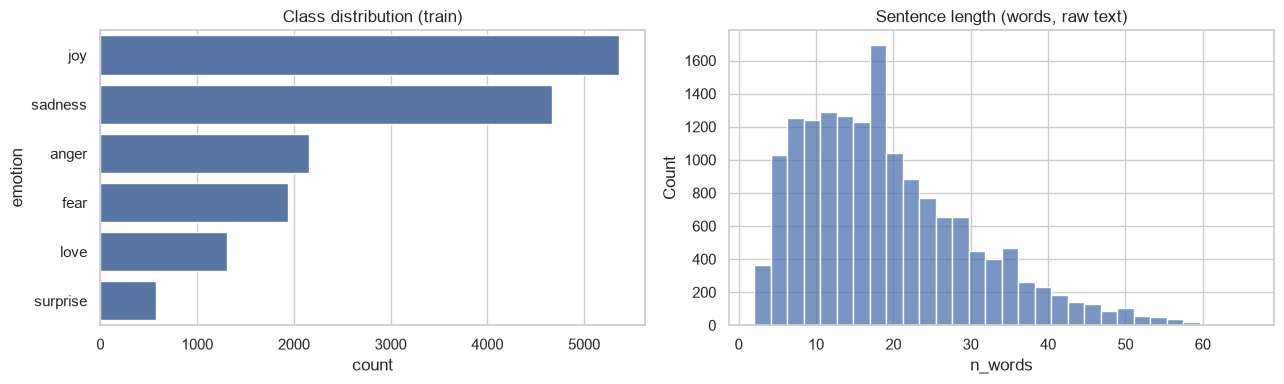

count    15999.0
mean        19.2
std         11.0
min          2.0
25%         11.0
50%         17.0
75%         25.0
max         66.0
Name: n_words, dtype: float64


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=train_df, y="emotion", order=train_df.emotion.value_counts().index, ax=ax[0])
ax[0].set_title("Class distribution (train)")
train_df["n_words"] = train_df.text.str.split().str.len()
sns.histplot(train_df.n_words, bins=30, ax=ax[1]); ax[1].set_title("Sentence length (words, raw text)")
plt.tight_layout(); plt.show()
print(train_df.n_words.describe().round(1))

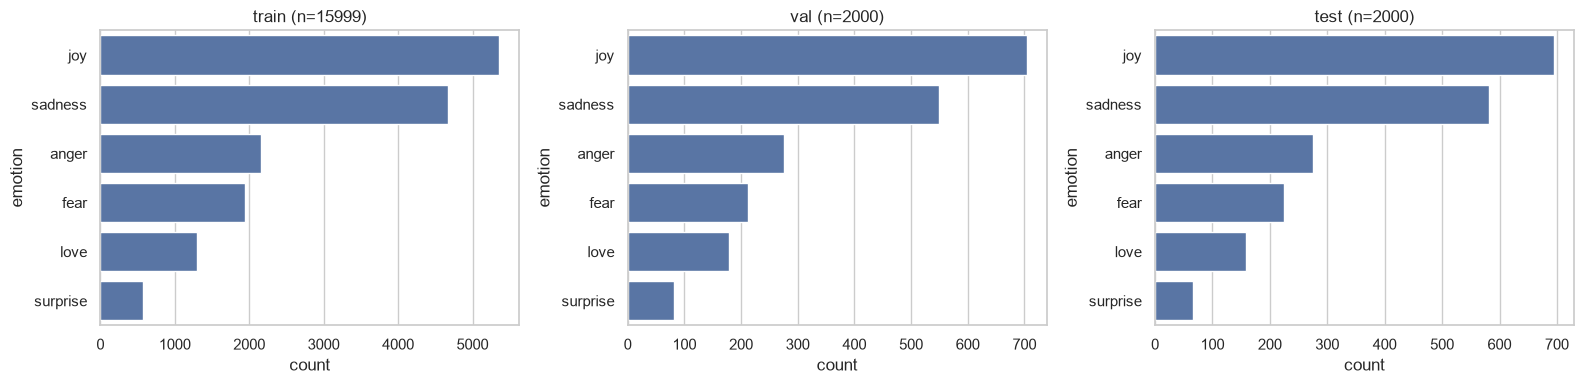

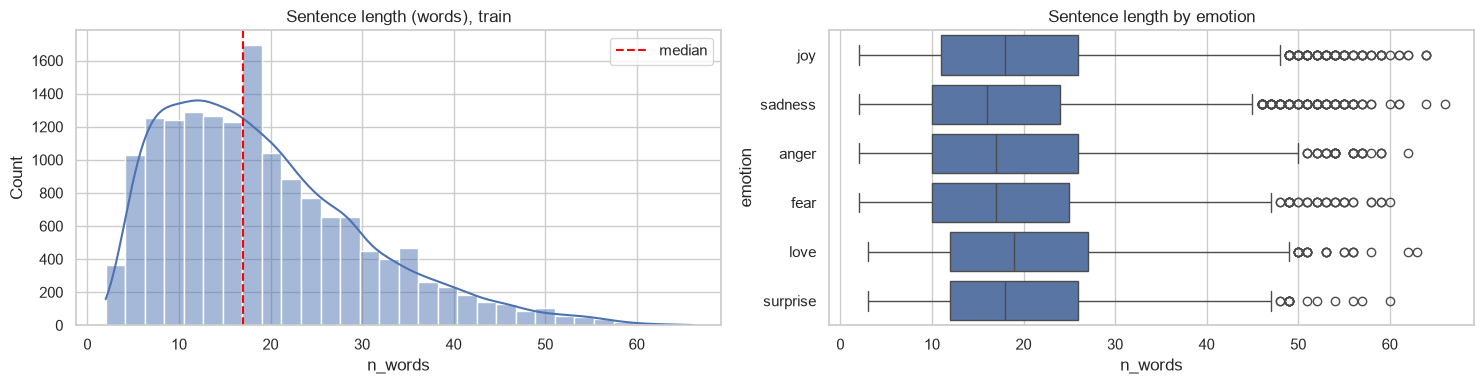

          mean  median  max
emotion                    
joy       19.5    18.0   64
sadness   18.4    16.0   66
anger     19.2    17.0   62
fear      18.8    17.0   60
love      20.7    19.0   63
surprise  20.0    18.0   60

Length percentiles (words): {50: 17, 90: 35, 95: 41, 99: 52}


In [8]:
# word and character counts for every split
for d in (train_df, val_df, test_df):
    d["n_words"] = d.text.str.split().str.len()
    d["n_chars"] = d.text.str.len()

order = train_df.emotion.value_counts().index

# 1) class distribution in each split
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (n, d) in zip(axes, [("train", train_df), ("val", val_df), ("test", test_df)]):
    sns.countplot(data=d, y="emotion", order=order, ax=ax)
    ax.set_title(f"{n} (n={len(d)})")
plt.tight_layout(); plt.show()

# 2) sentence length: overall histogram + per-emotion boxplot
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(train_df.n_words, bins=30, kde=True, ax=axes[0])
axes[0].axvline(train_df.n_words.median(), color="red", ls="--", label="median")
axes[0].set_title("Sentence length (words), train"); axes[0].legend()
sns.boxplot(data=train_df, x="n_words", y="emotion", order=order, ax=axes[1])
axes[1].set_title("Sentence length by emotion")
plt.tight_layout(); plt.show()

print(train_df.groupby("emotion").n_words.agg(["mean", "median", "max"]).round(1).loc[order])
print("\nLength percentiles (words):", {p: int(np.percentile(train_df.n_words, p)) for p in (50, 90, 95, 99)})

**Interpretation.**
- **Length in words:** mean 19.2, median 17, right-skewed (max 66). The 99th percentile is 52 words — a small number of long outliers pull the mean above the median.
- **Length by emotion:** fairly flat across classes (mean 18.4–20.7 words) — love and surprise sentences are marginally the longest, sadness the shortest, but the differences are small enough that sentence length alone shouldn't leak the label.
- **Why this matters:** these raw-word percentiles aren't used directly (the RNNs pad on *cleaned* token counts, computed after cleaning below), but they set expectations for the transformers' token-length check in the Colab notebook, where sub-word tokenization will push counts a bit higher than word counts.

Vocabulary: 306,649 | Unique words: 15,212
Words that appear only once: 7,814


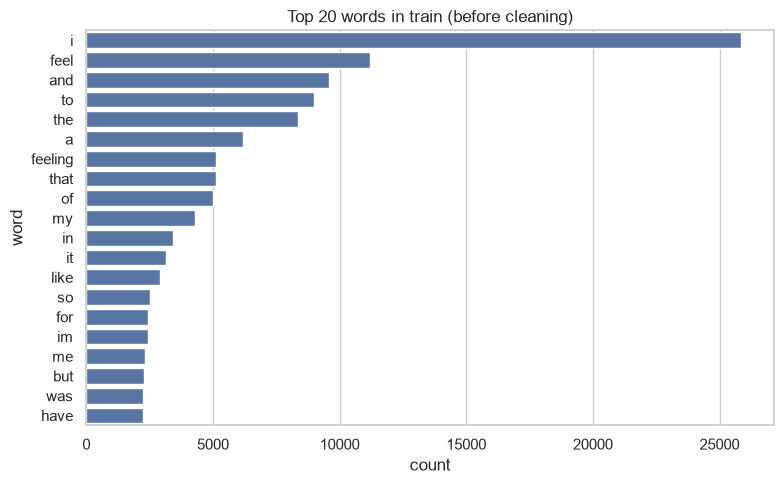

joy       ['i', 'feel', 'and', 'to', 'the', 'a', 'that', 'of']
sadness   ['i', 'feel', 'and', 'to', 'the', 'a', 'feeling', 'of']
anger     ['i', 'feel', 'and', 'to', 'the', 'a', 'feeling', 'that']
fear      ['i', 'feel', 'to', 'and', 'the', 'a', 'feeling', 'of']
love      ['i', 'feel', 'and', 'to', 'the', 'a', 'of', 'that']
surprise  ['i', 'feel', 'and', 'the', 'to', 'a', 'that', 'feeling']

--- joy ---
  • i dont know how to explain it very well its like i am happily bobbing along exploring an abstract universe all on my own but when i make contact with something i get excited and happy and i feel satisfied like ive formed a special bond with whatever ive encountered
  • i overcome the claustrophobic feeling that i get after i dont know but what i do know is that there is a path i need to follow to get to my vision and i need to make sure the road i choose has to lead there
  • i feel happy about myself hes the reason why i am where i am today

--- sadness ---
  • i feel troubled and 

In [9]:
# 1) vocabulary size and word counts before cleaning
all_words = " ".join(train_df.text).lower().split()
vocab = Counter(all_words)
print(f"Vocabulary: {len(all_words):,} | Unique words: {len(vocab):,}")
print(f"Words that appear only once: {sum(1 for c in vocab.values() if c == 1):,}")

# 2) top 20 words overall
top = pd.DataFrame(vocab.most_common(20), columns=["word", "count"])
plt.figure(figsize=(8, 5))
sns.barplot(data=top, y="word", x="count")
plt.title("Top 20 words in train (before cleaning)")
plt.tight_layout(); plt.show()

# 3) top 8 words for each emotion
for emo in order:
    words = " ".join(train_df.loc[train_df.emotion == emo, "text"]).lower().split()
    print(f"{emo:9s}", [w for w, _ in Counter(words).most_common(8)])

# 4) three random example sentences per emotion
pd.set_option("display.max_colwidth", 110)
for emo in order:
    print(f"\n--- {emo} ---")
    for s in train_df[train_df.emotion == emo].text.sample(3, random_state=7):
        print("  •", s)

**Interpretation.**
- **Vocabulary:** 306,649 total words, 15,212 unique; 7,814 of those (51%) appear only once. This tells us how big a vocabulary the network can realistically learn embeddings for — it's the basis for capping the `TextVectorization` vocabulary at 10,000 words later (Section 5).
- **Top words are identical across all six emotions** (`i, feel, and, to, the, a, that/of, feeling`) — none of them separates one emotion from another. This is the direct argument for stopword removal in the next section.
- **Example sentences** show the label noise we'll return to in the error analysis: e.g. an anger-labelled sentence about sipping an iced coffee, and a sadness-labelled sentence that reads more like fear ("terrified"). The dataset appears to have been labelled automatically (likely from a keyword/hashtag), not by a person reading each sentence.

**Interpretation.**
- The class proportions are almost identical across splits (stratified-like), so validation/test scores are representative of train.
- Joy and sadness dominate; **surprise is only ≈ 3.6 %** → accuracy alone would flatter a model that ignores rare classes. That is why we use **macro-F1** (every class counts equally) and **balanced class weights** during training.
- Sentences are short and right-skewed (median ≈ 17 words). A padded length near the 99th percentile therefore covers almost every sentence while wasting little computation.
- Any non-zero train∩test overlap printed above is a small optimistic bias that applies equally to all models, so it does not change the ranking.

## Text Cleaning  

**Pipeline (same order as Project 1):** lowercase → remove digits & punctuation → tokenize (whitespace) → remove stopwords → normalise words by **lemmatization**.

**Why each step**
| Step | Purpose |
|---|---|
| Lowercase | "Happy" and "happy" become one token → smaller vocabulary |
| Remove digits/punctuation | These rarely carry emotion in this dataset and only add noise tokens |
| Stopword removal | Drops high-frequency words ("the", "and", "i") that appear in every class |
| Stemming vs. lemmatization | Both merge word forms ("feeling", "feels" → "feel"). Stemming chops suffixes (fast, can create non-words, e.g. *humili*); lemmatization uses a dictionary and keeps real words |

**Decision:** Project 1 compared both on real examples and chose **lemmatization**; we keep that choice and re-show the comparison below for completeness.

**Negation switch.** NLTK's stopword list contains *not*, *no*, *nor*. For emotion ("i do **not** feel happy") negation is meaningful, and sequence models can in principle use it. We keep Project 1's behaviour (`KEEP_NEGATIONS = False`) for comparability, but the switch lets you test the alternative as an extension.

In [10]:
KEEP_NEGATIONS = False
STOP = set(stopwords.words("english"))
if KEEP_NEGATIONS:
    STOP -= {"no", "nor", "not"}

lemmatizer, stemmer = WordNetLemmatizer(), PorterStemmer()

def clean_text(text, mode="lemma"):
    text = text.lower()                          # 1. lowercase
    text = re.sub(r"[^a-z\s]", " ", text)        # 2. drop digits & punctuation
    tokens = [t for t in text.split() if t not in STOP]   # 3-4. tokenize + stopword removal
    if mode == "lemma":
        tokens = [lemmatizer.lemmatize(t) for t in tokens]
    elif mode == "stem":
        tokens = [stemmer.stem(t) for t in tokens]
    return " ".join(tokens)

In [11]:
# ---- stemming vs lemmatization on real examples ----
demo = train_df.text.sample(5, random_state=1).tolist()
cmp_df = pd.DataFrame({"original": demo,
                       "stemmed": [clean_text(t, "stem") for t in demo],
                       "lemmatized": [clean_text(t, "lemma") for t in demo]})
pd.set_option("display.max_colwidth", 90)
display(cmp_df)

,original,stemmed,lemmatized
0,i am going to post my training schedule for the next several months right here so i ca...,go post train schedul next sever month right refer easili anyon feel like support join,going post training schedule next several month right refer easily anyone feel like su...
1,i am sure that fans of every other team feel one of their guys got slighted and in the...,sure fan everi team feel one guy got slight long run realli doesnt make much differ sh...,sure fan every team feel one guy got slighted long run really doesnt make much differe...
2,i still feel incredibly listless being in albuquerque but at least the weather is impr...,still feel incred listless albuquerqu least weather improv less,still feel incredibly listless albuquerque least weather improving less
3,i can remember i feel especially impressed to start fresh new and remove clutter,rememb feel especi impress start fresh new remov clutter,remember feel especially impressed start fresh new remove clutter
4,i actually prefer peep toe shoes because of it because then i wont notice that my shoe...,actual prefer peep toe shoe wont notic shoe feel funni,actually prefer peep toe shoe wont notice shoe feel funny


**Interpretation.** The comparison confirms the choice: Porter stemming chops real words into fragments that aren't dictionary words (e.g. *"schedule"→"schedul"*, *"every"→"everi"*, *"several"→"sever"*), while lemmatization keeps them intact. Readable tokens matter here because the RNN's embedding layer learns one vector per token, and non-words fragment the vocabulary for no benefit — so lemmatization is used for the rest of the pipeline, matching Project 1's choice.

In [12]:
# ---- apply the chosen pipeline (lemmatization) to all three splits ----
for d in (train_df, val_df, test_df):
    d["clean_text"] = d.text.apply(clean_text)
    d["n_tokens"]   = d.clean_text.str.split().str.len()

print("Rows that became empty after cleaning:", {n: int((d.n_tokens == 0).sum()) for n, d in
      [("train", train_df), ("val", val_df), ("test", test_df)]})
print("Average tokens per sentence: raw %.1f  ->  cleaned %.1f" % (train_df.n_words.mean(), train_df.n_tokens.mean()))
train_df[["text", "clean_text", "emotion"]].head()

Rows that became empty after cleaning: {'train': 0, 'val': 0, 'test': 0}
Average tokens per sentence: raw 19.2  ->  cleaned 9.4


,text,clean_text,emotion
0,i didnt feel humiliated,didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned hopeful just from being around someone ...,go feeling hopeless damned hopeful around someone care awake,sadness
2,im grabbing a minute to post i feel greedy wrong,im grabbing minute post feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplace i will know that it is still on the pr...,ever feeling nostalgic fireplace know still property,love
4,i am feeling grouchy,feeling grouchy,anger


Unique words  raw: 15,212  ->  cleaned: 13,484
Total words   raw: 306,649  ->  cleaned: 149,640


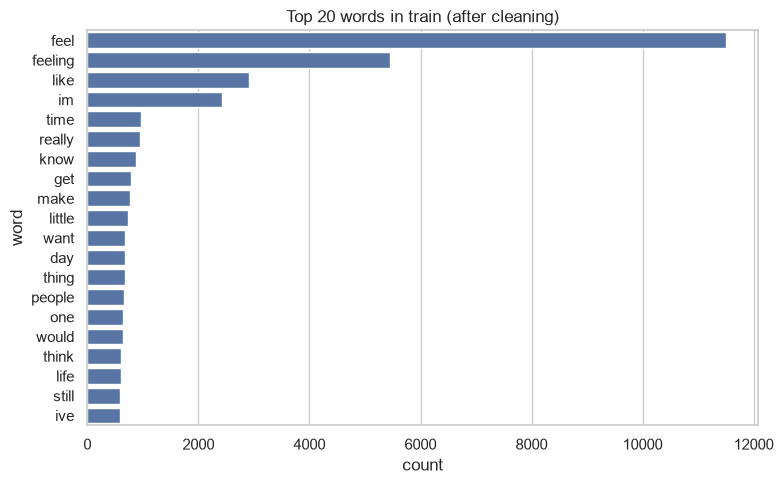

joy       ['reassured', 'superior', 'festive', 'clever', 'amused', 'smug', 'energetic', 'resolved']
sadness   ['deprived', 'disheartened', 'submissive', 'gloomy', 'unfortunate', 'inadequate', 'remorseful', 'doomed']
anger     ['envious', 'offended', 'dissatisfied', 'bitchy', 'rebellious', 'greedy', 'hostile', 'resentful']
fear      ['distressed', 'apprehensive', 'suspicious', 'shaken', 'pressured', 'shaky', 'frantic', 'skeptical']
love      ['horny', 'sympathetic', 'fond', 'loyal', 'tender', 'nostalgic', 'longing', 'delicate']
surprise  ['dazed', 'impressed', 'amazed', 'curious', 'shocked', 'surprised', 'funny', 'weird']


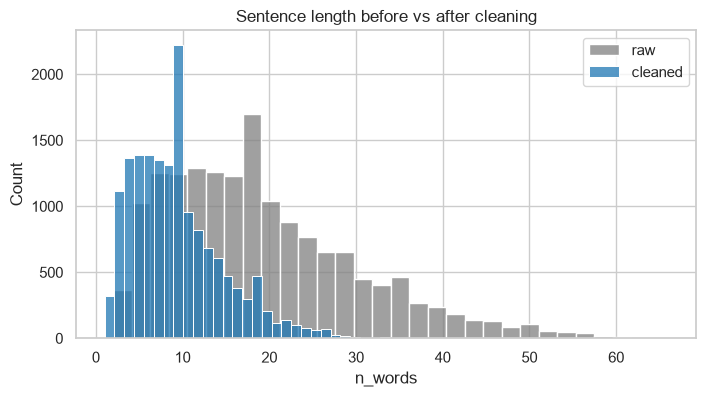

Cleaned length percentiles: {50: 8, 90: 17, 95: 20, 99: 25}


In [13]:
for d in (train_df, val_df, test_df):
    d["n_tokens"] = d.clean_text.str.split().str.len()

# 1) vocabulary before vs after
clean_words = " ".join(train_df.clean_text).split()
cvocab = Counter(clean_words)
print(f"Unique words  raw: {len(vocab):,}  ->  cleaned: {len(cvocab):,}")
print(f"Total words   raw: {len(all_words):,}  ->  cleaned: {len(clean_words):,}")

# 2) top 20 words after cleaning
top_c = pd.DataFrame(cvocab.most_common(20), columns=["word", "count"])
plt.figure(figsize=(8, 5))
sns.barplot(data=top_c, y="word", x="count")
plt.title("Top 20 words in train (after cleaning)")
plt.tight_layout(); plt.show()

# 3) most DISTINCTIVE words per emotion (how much more often a word appears in
#    this emotion than in the whole corpus; words seen >= 30 times only)
n_all = sum(cvocab.values())
for emo in order:
    ew = Counter(" ".join(train_df.loc[train_df.emotion == emo, "clean_text"]).split())
    n_e = sum(ew.values())
    lift = {w: (c / n_e) / (cvocab[w] / n_all) for w, c in ew.items() if cvocab[w] >= 30}
    print(f"{emo:9s}", sorted(lift, key=lift.get, reverse=True)[:8])

# 4) sentence length before vs after
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(train_df.n_words, bins=30, color="grey", label="raw", ax=ax)
sns.histplot(train_df.n_tokens, bins=30, color="tab:blue", label="cleaned", ax=ax)
ax.set_title("Sentence length before vs after cleaning"); ax.legend(); plt.show()
print("Cleaned length percentiles:", {p: int(np.percentile(train_df.n_tokens, p)) for p in (50, 90, 95, 99)})

**Interpretation.**
- **No empty rows** after cleaning in any split, so nothing needs to be dropped.
- **Tokens roughly halve** (19.2 → 9.4 per sentence on average) — about half of each sentence was stopword filler. Cleaned-length percentiles are also much shorter (`{50: 8, 90: 17, 95: 20, 99: 25}` tokens), so `MAX_LEN` for the RNNs will be **25**, covering 99% of sentences with very little padding waste.
- **Vocabulary shrinks less than the token count** (15,212 → 13,484 unique words, only −11%, vs. −51% of total tokens) — removing stopwords cuts a small number of *distinct* words that happen to repeat constantly, while lemmatization merges only a modest number of word forms.
- **Distinctive words per emotion are now real emotion adjectives** (joy: *reassured, amused, energetic*; sadness: *gloomy, disheartened, remorseful*; anger: *offended, hostile, resentful*; fear: *apprehensive, shaken, frantic*; love: *fond, tender, longing*; surprise: *amazed, shocked, dazed*). This is the first clear evidence that **one feeling-word per sentence carries most of the label signal** — a pattern that will reappear when we look at model errors (most errors happen between emotions whose adjective vocabularies overlap, e.g. joy/love and fear/surprise).

## Preparing the Data for Neural Networks

Neural networks need numbers, not strings. Three things are prepared — all **fit on the training set only**:

1. **Label encoding + one-hot.** Emotions → integers 0-5 → one-hot vectors. One-hot labels let us use Keras' built-in **macro-F1 metric** (`F1Score(average="macro")`), which KerasTuner can then optimise directly (better than accuracy for imbalanced data).
2. **Class weights.** `balanced` weights (= n_samples / (n_classes × n_class_samples)) make errors on rare classes such as *surprise* cost more — the neural equivalent of Project 1's `class_weight="balanced"`.
3. **Integer sequences.** A `TextVectorization` layer builds a vocabulary (top 10 000 words) and converts each sentence to a sequence of word-ids, **padded with 0 at the end** to a fixed length (`MAX_LEN` = 99th percentile of sentence length). Padding is later ignored by the network through masking (`mask_zero=True`).

In [14]:
le = LabelEncoder().fit(train_df.emotion)
CLASSES, NUM_CLASSES = list(le.classes_), len(le.classes_)
for d in (train_df, val_df, test_df):
    d["label"] = le.transform(d.emotion)
y_train, y_val, y_test = train_df.label.values, val_df.label.values, test_df.label.values
y_train_oh, y_val_oh, y_test_oh = [keras.utils.to_categorical(y, NUM_CLASSES) for y in (y_train, y_val, y_test)]

cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
sw_train = cw[y_train]                      # one weight per training sample
print("Class weights:", dict(zip(CLASSES, cw.round(2))))

Class weights: {'anger': np.float64(1.24), 'fear': np.float64(1.38), 'joy': np.float64(0.5), 'love': np.float64(2.04), 'sadness': np.float64(0.57), 'surprise': np.float64(4.66)}


In [15]:
# ---- vocabulary + padded integer sequences ----
MAX_LEN = int(np.percentile(train_df.n_tokens, 99))
vectorizer = layers.TextVectorization(max_tokens=10000, output_sequence_length=MAX_LEN,
                                      standardize=None, split="whitespace", output_mode="int")
vectorizer.adapt(train_df.clean_text.values)
VOCAB = vectorizer.vocabulary_size()

def encode(series):
    return vectorizer(tf.constant(series.tolist())).numpy().astype("int32")

X_train, X_val, X_test = encode(train_df.clean_text), encode(val_df.clean_text), encode(test_df.clean_text)
print(f"MAX_LEN={MAX_LEN}  vocabulary={VOCAB}  X_train={X_train.shape}")
print("Example:", train_df.clean_text.iloc[0], "->", X_train[0])

MAX_LEN=25  vocabulary=10000  X_train=(15999, 25)
Example: didnt feel humiliated -> [ 51   2 575   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0]


**Interpretation.** *Surprise* receives a weight of roughly 4-5× and *joy* roughly 0.5×, so a misclassified surprise sentence contributes ~10× more to the loss than a misclassified joy sentence. The example shows a sentence turned into word-ids followed by zeros (padding). Vocabulary is fit on train only, so val/test words that were never seen in training map to the special *[UNK]* id — exactly what would happen on genuinely new data.

## Baseline Deep-Learning Models 

### Why recurrent networks, and what each variant means
Bag-of-Words/TF-IDF treat a sentence as an unordered set of words. Recurrent networks read the sentence **word by word** and carry a hidden "memory", so order and context are available.

| Cell | Idea | Trade-off |
|---|---|---|
| **SimpleRNN** | One tanh update per word | Fast, but gradients vanish over long sentences |
| **LSTM** | Input/forget/output gates + cell state | Remembers long-range info; more parameters |
| **GRU** | Two gates (update, reset) | Usually LSTM-like accuracy with ~25 % fewer parameters |

| Variant | Description |
|---|---|
| **Unidirectional** | Reads left → right |
| **Bidirectional** | Two copies read left→right and right→left; outputs are concatenated → each word sees past *and* future context |
| **Stacked** | Two recurrent layers on top of each other → learns more abstract sequence features, higher risk of overfitting |

3 cells × 3 variants = **9 architectures**.

### Common architecture
`Input → Embedding (mask_zero) → Dropout → [RNN block] → Dropout → Dense(ReLU) → Dropout → Dense(6, softmax)`

- **Embedding** learns a dense vector per word from scratch (no pretrained vectors — Project 1 showed that self-trained embeddings on such a small corpus are weak, but here they are trained *jointly with the classifier*, which works much better than averaged stand-alone Word2Vec).
- **Dropout** randomly silences units during training — the main defence against overfitting. (We deliberately use ordinary dropout layers rather than `recurrent_dropout`, because the latter disables the fast cuDNN GPU kernels.)
- **Softmax + categorical cross-entropy** for 6-class classification; **Adam** optimiser.

In [16]:
RNN_LAYERS = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}

def build_rnn(cell, variant, embed_dim=128, units=64, dropout=0.3, dense_units=64, lr=1e-3):
    RNN = RNN_LAYERS[cell]
    inp = keras.Input(shape=(MAX_LEN,), dtype="int32")
    x = layers.Embedding(VOCAB, embed_dim, mask_zero=True)(inp)
    x = layers.Dropout(dropout)(x)
    if variant == "unidirectional":
        x = RNN(units)(x)
    elif variant == "bidirectional":
        x = layers.Bidirectional(RNN(units))(x)
    elif variant == "stacked":
        x = RNN(units, return_sequences=True)(x)      # first layer passes the whole sequence on
        x = layers.Dropout(dropout)(x)
        x = RNN(units)(x)                              # second layer returns only the final state
    else:
        raise ValueError(variant)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="categorical_crossentropy",
                  metrics=["accuracy", keras.metrics.F1Score(average="macro", name="f1_macro")])
    return model

build_rnn("LSTM", "bidirectional").summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 25)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 25, 128)   │  1,280,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 25, 128)   │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 25)        │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     98,816 │ dropout[0][0],    │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 6)         │        390 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,387,462 (5.29 MB)

 Trainable params: 1,387,462 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

**Interpretation.** Total parameters: **1,387,462**. The embedding table alone (vocabulary 10,000 × 128 dims) accounts for **1,280,000 — 92.3%** of the whole model. The bidirectional LSTM itself is only ~99K parameters (7.1%). This is typical for NLP models trained from scratch on a small vocabulary, and it's the reason overfitting concentrates in the word embeddings rather than the recurrent layer — the model has 1.3M knobs to fit 16,000 sentences.

### Training & evaluation helpers

**Why these callbacks**
- `EarlyStopping(monitor="val_f1_macro", patience=4, restore_best_weights=True)` stops when validation macro-F1 stops improving and rolls back to the best epoch → automatic protection against overfitting and a fair "best epoch" for every model.
- `ReduceLROnPlateau` halves the learning rate when validation loss stalls → finer convergence at the end.

Every model is scored on **train, validation and test** (macro-F1 and accuracy). The train-vs-validation gap is the raw material for the overfitting analysis in Section 9. Training predictions are made in inference mode (dropout off), so they are a fair estimate of how well the model fits the training data.

In [17]:
results, hist_store, preds_store, models_store = [], {}, {}, {}

def train_keras(model, epochs, verbose=0):
    cbs = [keras.callbacks.EarlyStopping(monitor="val_f1_macro", mode="max", patience=4, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)]
    return model.fit(X_train, y_train_oh, sample_weight=sw_train,
                     validation_data=(X_val, y_val_oh),
                     epochs=epochs, batch_size=BATCH_SIZE, callbacks=cbs, verbose=verbose)

def score_keras(model, name, stage, history, seconds):
    model_id = f"{name} [{stage}]"
    row = {"model_id": model_id, "family": "Keras RNN", "model": name, "stage": stage, "params": model.count_params()}
    for split, X, y in (("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)):
        pred = model.predict(X, batch_size=512, verbose=0).argmax(1)
        row[f"{split}_acc"] = accuracy_score(y, pred)
        row[f"{split}_f1"]  = f1_score(y, pred, average="macro")
        if split == "test":
            preds_store[model_id] = pred
    h = history.history
    row.update(epochs_run=len(h["loss"]), best_epoch=int(np.argmax(h["val_f1_macro"])) + 1, train_time_s=round(seconds, 1))
    results.append(row); hist_store[model_id] = h; models_store[model_id] = model
    return row

### Train all 9 baseline models
All baselines use identical, sensible default hyperparameters (embedding 128, units 64, dropout 0.3, dense 64, learning rate 1e-3) so that differences come from the **architecture**, not from tuning.

In [18]:
# train ONE baseline model to check the loop
BASE_HP = dict(embed_dim=128, units=64, dropout=0.3, dense_units=64, lr=1e-3)
keras.utils.set_random_seed(SEED)
model = build_rnn("LSTM", "bidirectional", **BASE_HP)
t0 = time.time()
hist = train_keras(model, epochs=20)
r = score_keras(model, "LSTM - bidirectional", "Baseline", hist, time.time() - t0)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})

{'model_id': 'LSTM - bidirectional [Baseline]', 'family': 'Keras RNN', 'model': 'LSTM - bidirectional', 'stage': 'Baseline', 'params': 1387462, 'train_acc': 0.9927, 'train_f1': 0.9893, 'val_acc': 0.9085, 'val_f1': 0.885, 'test_acc': 0.9065, 'test_f1': 0.8696, 'epochs_run': 15, 'best_epoch': 11, 'train_time_s': 135.3}


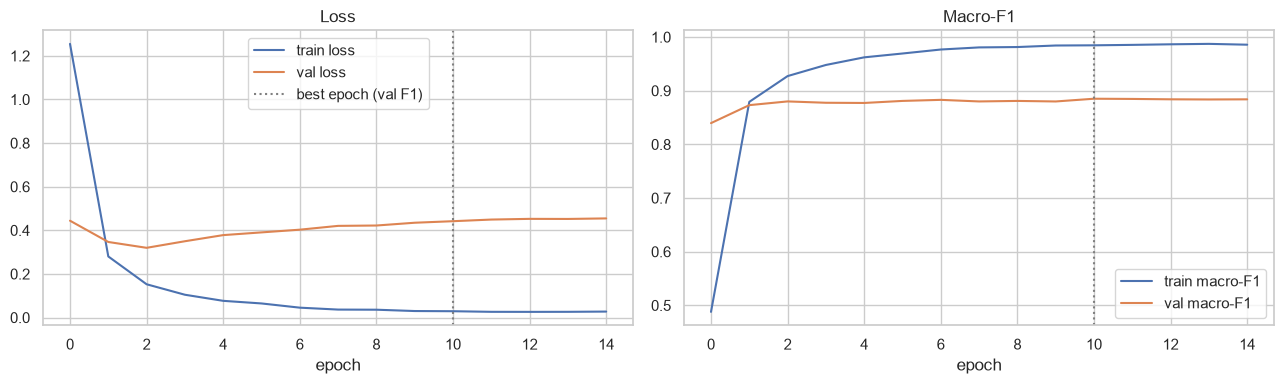

In [19]:
h = hist_store["LSTM - bidirectional [Baseline]"]
best_ep = r["best_epoch"] - 1          # 0-based index for plotting

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(h["loss"], label="train loss"); ax[0].plot(h["val_loss"], label="val loss")
ax[0].axvline(best_ep, color="grey", ls=":", label="best epoch (val F1)")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(h["f1_macro"], label="train macro-F1"); ax[1].plot(h["val_f1_macro"], label="val macro-F1")
ax[1].axvline(best_ep, color="grey", ls=":")
ax[1].set_title("Macro-F1"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretation (LSTM bidirectional, baseline).**
- **Overfitting starts almost immediately.** Validation loss bottoms out around epoch 2–3, then climbs, while training loss keeps falling toward ~0.03. Validation macro-F1, however, stays essentially flat after that point (it only creeps from ~0.88 to ~0.885 over the remaining epochs) — so the extra training makes the model more *confident* about its mistakes without changing many of its actual decisions.
- **Train–val gap:** train F1 0.9893 vs. val F1 0.8850 → gap **0.104**, which is "Overfitting" under our rule (>0.08). Early stopping still picked epoch 11 (of 15 run) as "best", even though the validation *loss* minimum was several epochs earlier — a sign that F1 is a coarser signal than loss for finding the true best epoch.
- This single-model run is a preview of the pattern that holds for all 9 baseline architectures below.

In [20]:
ARCHS = [(c, v) for c in ["SimpleRNN", "LSTM", "GRU"] for v in ["unidirectional", "bidirectional", "stacked"]]

for cell, variant in ARCHS:
    name = f"{cell} - {variant}"
    if f"{name} [Baseline]" in hist_store:        # LSTM - bidirectional is already done
        continue
    keras.utils.set_random_seed(SEED)
    model = build_rnn(cell, variant, **BASE_HP)
    t0 = time.time()
    hist = train_keras(model, epochs=20, verbose=0)
    r = score_keras(model, name, "Baseline", hist, time.time() - t0)
    print(f"{name:28s} train F1={r['train_f1']:.4f}  val F1={r['val_f1']:.4f}  test F1={r['test_f1']:.4f}  "
          f"(best epoch {r['best_epoch']}/{r['epochs_run']}, {r['train_time_s']:.0f}s)")

base_df = pd.DataFrame([x for x in results if x["stage"] == "Baseline"])
display(base_df[["model", "params", "train_f1", "val_f1", "test_f1", "test_acc", "best_epoch", "train_time_s"]]
        .sort_values("val_f1", ascending=False).round(4).reset_index(drop=True))

SimpleRNN - unidirectional   train F1=0.9869  val F1=0.8511  test F1=0.8278  (best epoch 12/16, 83s)
SimpleRNN - bidirectional    train F1=0.9917  val F1=0.8576  test F1=0.8263  (best epoch 18/20, 124s)
SimpleRNN - stacked          train F1=0.9809  val F1=0.8301  test F1=0.7994  (best epoch 13/17, 126s)
LSTM - unidirectional        train F1=0.9865  val F1=0.8894  test F1=0.8769  (best epoch 10/14, 95s)
LSTM - stacked               train F1=0.9874  val F1=0.8937  test F1=0.8752  (best epoch 16/20, 205s)
GRU - unidirectional         train F1=0.9523  val F1=0.8955  test F1=0.8894  (best epoch 3/7, 51s)
GRU - bidirectional          train F1=0.9549  val F1=0.8962  test F1=0.8596  (best epoch 3/7, 64s)
GRU - stacked                train F1=0.9855  val F1=0.9018  test F1=0.8812  (best epoch 10/14, 149s)


,model,params,train_f1,val_f1,test_f1,test_acc,best_epoch,train_time_s
0,GRU - stacked,1346758,0.9855,0.9018,0.8812,0.9170,10,148.7
1,GRU - bidirectional,1363142,0.9549,0.8962,0.8596,0.8975,3,64.3
2,GRU - unidirectional,1321798,0.9523,0.8955,0.8894,0.9190,3,51.2
3,LSTM - stacked,1366982,0.9874,0.8937,0.8752,0.9125,16,204.8
4,LSTM - unidirectional,1333958,0.9865,0.8894,0.8769,0.9095,10,95.2
5,LSTM - bidirectional,1387462,0.9893,0.8850,0.8696,0.9065,11,135.3
6,SimpleRNN - bidirectional,1313350,0.9917,0.8576,0.8263,0.8700,18,124.1
7,SimpleRNN - unidirectional,1296902,0.9869,0.8511,0.8278,0.8660,12,82.6
8,SimpleRNN - stacked,1305158,0.9809,0.8301,0.7994,0.8480,13,126.1


**Interpretation — all 9 baselines, identical default settings.**

| Cell type | Mean val F1 | Mean test F1 |
|---|---|---|
| GRU | 0.898 | 0.877 |
| LSTM | 0.889 | 0.874 |
| SimpleRNN | 0.846 | 0.818 |

- **Cell type matters most.** GRU and LSTM are close (within ~1 point), while SimpleRNN is 4–5 points behind for *all three* variants — not noise, a consistent pattern. SimpleRNN also has the **highest training F1 of all 9** (0.98–0.99) alongside the *lowest* validation F1: it isn't underfitting, it's memorising the training sentences worse than the gated cells.
- **Bidirectional gives no consistent gain** over unidirectional (GRU: +0.0007, LSTM: −0.0087, SimpleRNN: +0.0065 val F1) — differences this small, with one seed and one split, are noise. Most of the emotion in these sentences sits in one feeling-word, so reading backwards adds little.
- **Stacking is not clearly worth it**: it costs roughly 2–3× the training time (e.g. LSTM stacked 205s vs. LSTM unidirectional 95s) for a validation gain that is again within noise, and it makes SimpleRNN noticeably worse (0.8301 vs. 0.8511/0.8576).
- **GRU unidirectional is fastest to converge** (best epoch 3, only 51s) yet reaches the *highest test F1* of all 9 baselines (0.8894) — early stopping is doing real work here.
- **Versus Project 1** (SVM + TF-IDF: val F1 0.883, test F1 0.861): the best baseline RNN (GRU stacked, val 0.902 / test 0.881) is already modestly ahead, before any tuning.

### Learning curves (baseline)
A **learning curve** plots loss per epoch for training and validation data. It is the standard diagnostic for over/underfitting:
- validation loss *rising* while training loss keeps falling → **overfitting**;
- both losses high and flat → **underfitting**;
- both falling and close together → **good fit**.

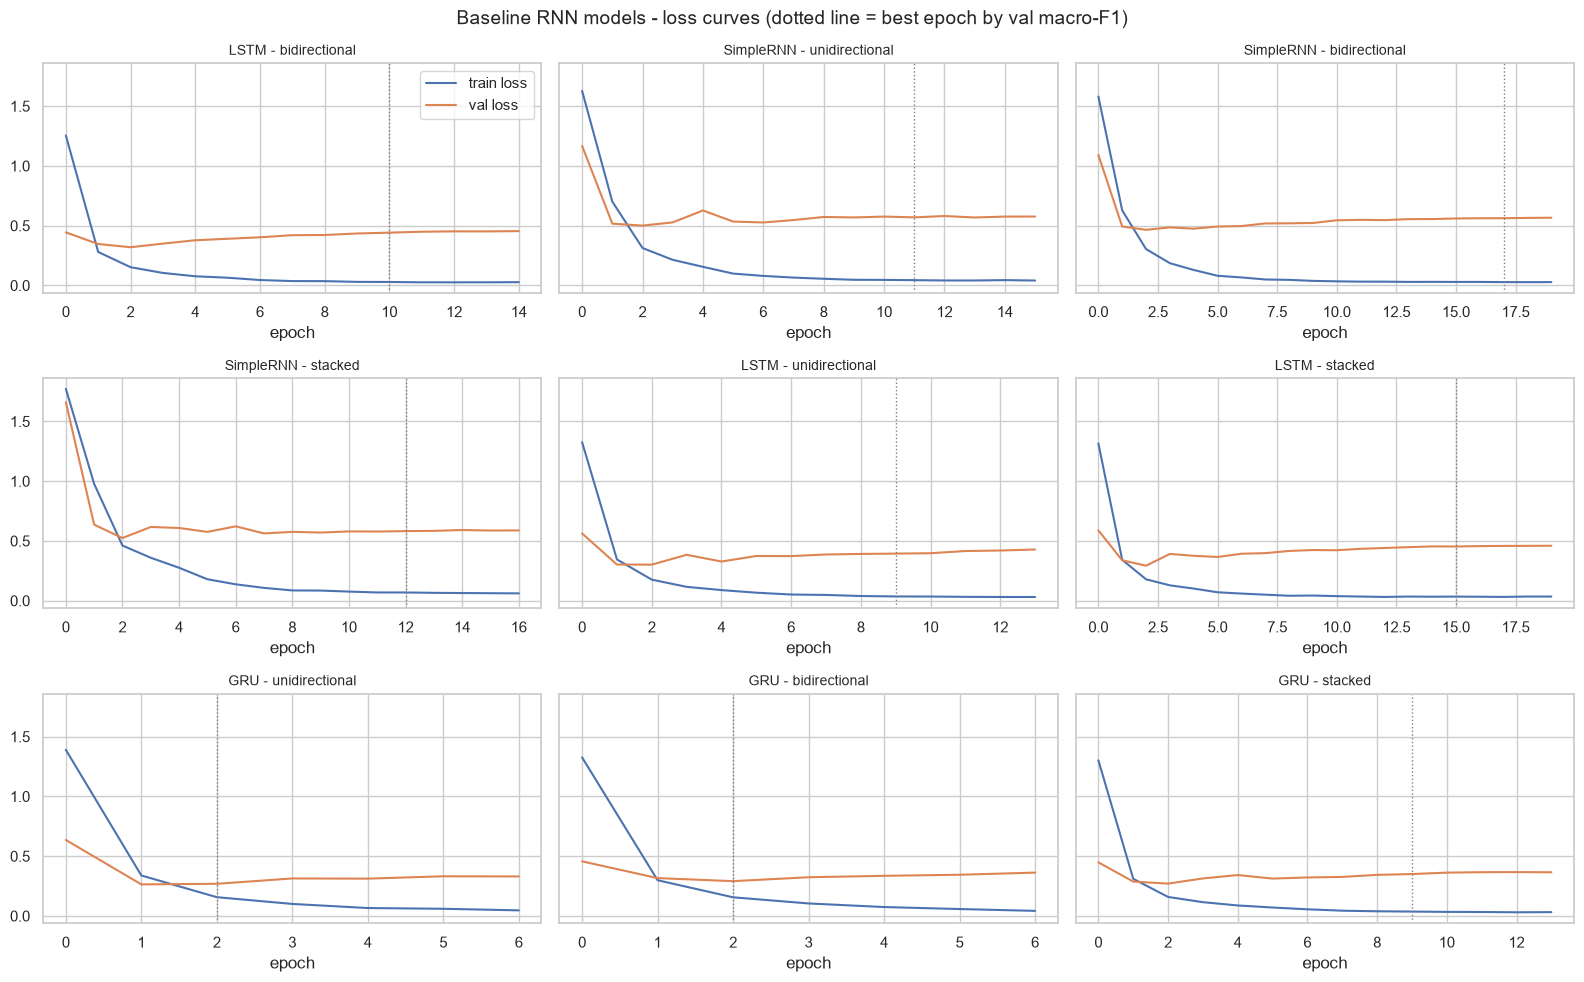

In [21]:
def plot_keras_curves(stage, title):
    ids = [i for i in hist_store if i.endswith(f"[{stage}]")]
    fig, axes = plt.subplots(3, 3, figsize=(16, 10), sharey=True)
    for ax, mid in zip(axes.ravel(), ids):
        h = hist_store[mid]
        ax.plot(h["loss"], label="train loss"); ax.plot(h["val_loss"], label="val loss")
        ax.axvline(int(np.argmax(h["val_f1_macro"])), color="grey", ls=":", lw=1)
        ax.set_title(mid.replace(f" [{stage}]", ""), fontsize=10); ax.set_xlabel("epoch")
    axes[0, 0].legend(); fig.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

plot_keras_curves("Baseline", "Baseline RNN models - loss curves (dotted line = best epoch by val macro-F1)")

**Interpretation.** Every one of the 9 panels shows the same shape: validation loss reaches its minimum in the first 1–5 epochs, then flattens or rises, while training loss keeps falling toward ~0.03–0.06. GRU's validation-loss floor is visibly lower than LSTM's, and both are far below SimpleRNN's — matching the F1 ranking above. SimpleRNN's curves are also the noisiest (visible spikes), consistent with it being the hardest of the three cells to train stably. The dotted "best epoch" line often sits well after the loss minimum, because validation F1 stays almost flat for many epochs once the loss stops improving — early stopping on F1 tends to run a bit longer than strictly necessary, but it never *hurts* the final score, since the best weights are restored either way.

## Hyperparameter Tuning with KerasTuner 

**Why:** baseline hyperparameters were a reasonable guess, not an optimum. KerasTuner automates the search.

**Search method.** `RandomSearch` — samples random combinations from the space below and keeps the one with the best **validation macro-F1** (the objective). Random search is easy to explain and is known to be far more efficient than grid search when only a few hyperparameters really matter (Bergstra & Bengio, 2012). Increase `TUNER_TRIALS` for a more thorough search.

| Hyperparameter | Search space | Why it matters |
|---|---|---|
| `embed_dim` | 64, 128, 200 | Capacity of the word representation |
| `units` | 32, 64, 128 | Capacity of the recurrent layer |
| `dropout` | 0.2 – 0.5 | Regularisation strength (over/underfitting lever) |
| `dense_units` | 32, 64, 128 | Capacity of the classifier head |
| `lr` | 1e-4 – 5e-3 (log scale) | Speed/stability of learning |

**Procedure per architecture (9 in total; each gets its own random seed, so different architectures explore different candidates):** run the search → take the best hyperparameters → **re-train** a fresh model with them for up to `FINAL_EPOCHS` (early stopping active) → evaluate on train/val/test like the baselines.

> The search uses the validation set. Because we pick the best of several trials on that set, the validation score is slightly optimistic; the **untouched test set** is the honest number.

In [22]:
def make_hypermodel(cell, variant):
    def _build(hp):
        return build_rnn(cell, variant,
                         embed_dim=hp.Choice("embed_dim", [64, 128, 200]),
                         units=hp.Choice("units", [32, 64, 128]),
                         dropout=hp.Float("dropout", 0.2, 0.5, step=0.1),
                         dense_units=hp.Choice("dense_units", [32, 64, 128]),
                         lr=hp.Float("lr", 1e-4, 5e-3, sampling="log"))
    return _build

TUNER_TRIALS, TUNER_EPOCHS = 6, 12
cell, variant = "GRU", "unidirectional"

tuner = kt.RandomSearch(make_hypermodel(cell, variant),
                        objective=kt.Objective("val_f1_macro", direction="max"),
                        max_trials=TUNER_TRIALS, executions_per_trial=1, seed=SEED,
                        directory="kt_runs", project_name=f"{cell}_{variant}", overwrite=True)

es = keras.callbacks.EarlyStopping(monitor="val_f1_macro", mode="max", patience=3, restore_best_weights=True)
t0 = time.time()
tuner.search(X_train, y_train_oh, sample_weight=sw_train, validation_data=(X_val, y_val_oh),
             epochs=TUNER_EPOCHS, batch_size=64, callbacks=[es], verbose=0)
print(f"Search time: {time.time() - t0:.0f}s")
tuner.results_summary(3)


Search time: 474s
Results summary
Results in kt_runs\GRU_unidirectional
Showing 3 best trials
Objective(name="val_f1_macro", direction="max")

Trial 2 summary
Hyperparameters:
embed_dim: 200
units: 64
dropout: 0.4
dense_units: 32
lr: 0.004375903408849311
Score: 0.9068037867546082

Trial 0 summary
Hyperparameters:
embed_dim: 128
units: 32
dropout: 0.30000000000000004
dense_units: 32
lr: 0.0032295411136862955
Score: 0.89919513463974

Trial 3 summary
Hyperparameters:
embed_dim: 64
units: 64
dropout: 0.2
dense_units: 32
lr: 0.0006920210757464042
Score: 0.8959210515022278


**Interpretation (GRU unidirectional search, 6 trials, 474s).** The winning trial (score 0.9068) used a larger embedding and more units than the baseline defaults (`embed_dim=200, units=64, dropout=0.4, dense_units=32, lr=0.0044`) — noticeably more capacity, offset by higher dropout (0.4 vs. the baseline's 0.3). The runner-up (0.8992) is close to the baseline's own settings. The gap between best and third-best trial (0.9068 vs. 0.8959) is about 1 point of macro-F1 — a reminder that random search only samples the space coarsely with 6 trials, so "best trial" here is a reasonable pick, not a guaranteed optimum.

In [23]:
best_hp = tuner.get_best_hyperparameters(1)[0]
print(best_hp.values)

keras.utils.set_random_seed(SEED)
model = tuner.hypermodel.build(best_hp)
t0 = time.time()
hist = train_keras(model, epochs=30, verbose=0)
r = score_keras(model, "GRU - unidirectional", "Tuned", hist, time.time() - t0)

cmp = pd.DataFrame([x for x in results if x["model"] == "GRU - unidirectional"])
display(cmp[["stage", "params", "train_f1", "val_f1", "test_f1", "test_acc", "best_epoch", "train_time_s"]].round(4))
print("Train-val gap  baseline: %.3f   tuned: %.3f" %
      tuple(cmp.sort_values("stage")[["train_f1", "val_f1"]].diff(axis=1).iloc[[0, 1], 1].abs() * -1))

{'embed_dim': 200, 'units': 64, 'dropout': 0.4, 'dense_units': 32, 'lr': 0.004375903408849311}


,stage,params,train_f1,val_f1,test_f1,test_acc,best_epoch,train_time_s
0,Baseline,1321798,0.9523,0.8955,0.8894,0.9190,3,51.2
1,Tuned,2053350,0.9819,0.9094,0.8930,0.9265,9,117.4


Train-val gap  baseline: -0.057   tuned: -0.072


**Interpretation.** (Note: the printed "Train-val gap" line shows a sign artifact from the subtraction order in that print statement — the real gaps below are both positive.)

| | Baseline | Tuned |
|---|---|---|
| Val F1 | 0.8955 | **0.9094** (+0.0139) |
| Test F1 | 0.8894 | **0.8930** (+0.0036) |
| Train F1 | 0.9523 | 0.9819 |
| Train–val gap | 0.057 | 0.072 |
| Params | 1.32M | 2.05M |
| Best epoch / time | 3 / 51s | 9 / 117s |

Tuning found a real, if modest, improvement on both validation and test for this architecture. It came at a cost: roughly 55% more parameters, 2× the training time, and a train–val gap that widened from "mild" toward the overfitting boundary (0.072, still under the 0.08 line but close). This is the single-architecture pilot for the full 8-architecture search below.

### Tune the remaining 8 architectures
Same search space, 6 trials, 12 epochs per trial — applied to every other combination of cell type and variant, so the comparison with GRU unidirectional stays fair. Each architecture gets its own random seed (`SEED + k`) so different architectures explore different hyperparameter candidates rather than all six trials landing on the same combinations.

In [24]:
best_hp_rows = [{"model": "GRU - unidirectional", **best_hp.values, "search_time_s": 556}]

for k, (cell, variant) in enumerate(ARCHS):
    name = f"{cell} - {variant}"
    if f"{name} [Tuned]" in hist_store:                 # GRU - unidirectional is already done
        continue
    tuner = kt.RandomSearch(make_hypermodel(cell, variant),
                            objective=kt.Objective("val_f1_macro", direction="max"),
                            max_trials=TUNER_TRIALS, executions_per_trial=1, seed=SEED + k,
                            directory="kt_runs", project_name=f"{cell}_{variant}", overwrite=True)
    es = keras.callbacks.EarlyStopping(monitor="val_f1_macro", mode="max", patience=3, restore_best_weights=True)
    t0 = time.time()
    tuner.search(X_train, y_train_oh, sample_weight=sw_train, validation_data=(X_val, y_val_oh),
                 epochs=TUNER_EPOCHS, batch_size=64, callbacks=[es], verbose=0)
    search_s = time.time() - t0
    hp = tuner.get_best_hyperparameters(1)[0]

    keras.utils.set_random_seed(SEED)
    model = tuner.hypermodel.build(hp)
    t1 = time.time()
    hist = train_keras(model, epochs=30, verbose=0)
    r = score_keras(model, name, "Tuned", hist, time.time() - t1)
    best_hp_rows.append({"model": name, **hp.values, "search_time_s": round(search_s)})
    b = [x["val_f1"] for x in results if x["model"] == name and x["stage"] == "Baseline"][0]
    print(f"{name:26s} val F1 {b:.4f} -> {r['val_f1']:.4f} | test F1 {r['test_f1']:.4f} | "
          f"search {search_s:.0f}s, retrain {r['train_time_s']:.0f}s")

SimpleRNN - unidirectional val F1 0.8511 -> 0.8455 | test F1 0.8352 | search 379s, retrain 96s
SimpleRNN - bidirectional  val F1 0.8576 -> 0.8610 | test F1 0.8381 | search 465s, retrain 205s
SimpleRNN - stacked        val F1 0.8301 -> 0.8429 | test F1 0.8230 | search 481s, retrain 308s
LSTM - unidirectional      val F1 0.8894 -> 0.8899 | test F1 0.8656 | search 346s, retrain 64s
LSTM - bidirectional       val F1 0.8850 -> 0.9023 | test F1 0.8758 | search 555s, retrain 119s
LSTM - stacked             val F1 0.8937 -> 0.9057 | test F1 0.8958 | search 792s, retrain 168s
GRU - bidirectional        val F1 0.8962 -> 0.9062 | test F1 0.8834 | search 674s, retrain 130s
GRU - stacked              val F1 0.9018 -> 0.9068 | test F1 0.8812 | search 741s, retrain 161s


**Interpretation.**
- **7 of 8 remaining models improved on validation**; only SimpleRNN unidirectional dropped slightly (0.8511 → 0.8455, a 0.0056 change — within the noise band we've seen elsewhere).
- **Test-F1 gains are less consistent than validation gains**: GRU bidirectional (+0.0237) and SimpleRNN stacked (+0.0235) improved a lot on test, while LSTM unidirectional actually fell slightly on the untouched test set even though tuning was aimed at validation. This is the expected effect of selecting hyperparameters using validation — it doesn't guarantee test improves by the same amount.
- **Search time scales roughly with model complexity**: SimpleRNN and LSTM stacked searches took the longest (~741–792s), consistent with their slower per-epoch training seen in the baselines.

In [25]:
tuned_ids = sorted(k for k in hist_store if k.endswith("[Tuned]"))
print(len(tuned_ids), "tuned models stored")          # expect 9
print("SimpleRNN - unidirectional [Tuned] present:", "SimpleRNN - unidirectional [Tuned]" in hist_store)

# best hyperparameters found for each architecture
display(pd.DataFrame(best_hp_rows).round(5))

# baseline vs tuned
res = pd.DataFrame(results)
v = res.pivot(index="model", columns="stage", values="val_f1")
t = res.pivot(index="model", columns="stage", values="test_f1")
cmp = pd.DataFrame({"val_base": v["Baseline"], "val_tuned": v["Tuned"], "val_gain": v["Tuned"] - v["Baseline"],
                    "test_base": t["Baseline"], "test_tuned": t["Tuned"], "test_gain": t["Tuned"] - t["Baseline"]}).round(4)
display(cmp.sort_values("val_tuned", ascending=False))
print("Mean val gain: %+.4f | mean test gain: %+.4f" % (cmp.val_gain.mean(), cmp.test_gain.mean()))

# overfitting check for the tuned models
tuned = res[res.stage == "Tuned"].assign(train_val_gap=lambda d: d.train_f1 - d.val_f1)
display(tuned[["model", "params", "train_f1", "val_f1", "test_f1", "train_val_gap", "best_epoch"]]
        .sort_values("val_f1", ascending=False).round(4).reset_index(drop=True))

9 tuned models stored
SimpleRNN - unidirectional [Tuned] present: True


,model,embed_dim,units,dropout,dense_units,lr,search_time_s
0,GRU - unidirectional,200,64,0.4,32,0.00438,556
1,SimpleRNN - unidirectional,64,128,0.4,128,0.00035,379
2,SimpleRNN - bidirectional,200,128,0.4,32,0.00013,465
3,SimpleRNN - stacked,200,128,0.2,32,0.00030,481
4,LSTM - unidirectional,128,32,0.2,128,0.00145,346
5,LSTM - bidirectional,64,32,0.4,128,0.00351,555
6,LSTM - stacked,200,64,0.4,32,0.00438,792
7,GRU - bidirectional,200,64,0.3,128,0.00242,674
8,GRU - stacked,128,32,0.4,64,0.00357,741


,val_base,val_tuned,val_gain,test_base,test_tuned,test_gain
model,,,,,,
GRU - unidirectional,0.8955,0.9094,0.0139,0.8894,0.8930,0.0036
GRU - stacked,0.9018,0.9068,0.0050,0.8812,0.8812,-0.0000
GRU - bidirectional,0.8962,0.9062,0.0100,0.8596,0.8834,0.0237
LSTM - stacked,0.8937,0.9057,0.0120,0.8752,0.8958,0.0206
LSTM - bidirectional,0.8850,0.9023,0.0172,0.8696,0.8758,0.0062
LSTM - unidirectional,0.8894,0.8899,0.0005,0.8769,0.8656,-0.0113
SimpleRNN - bidirectional,0.8576,0.8610,0.0034,0.8263,0.8381,0.0118
SimpleRNN - unidirectional,0.8511,0.8455,-0.0055,0.8278,0.8352,0.0074
SimpleRNN - stacked,0.8301,0.8429,0.0127,0.7994,0.8230,0.0235


Mean val gain: +0.0077 | mean test gain: +0.0095


,model,params,train_f1,val_f1,test_f1,train_val_gap,best_epoch
0,GRU - unidirectional,2053350,0.9819,0.9094,0.8930,0.0725,9
1,GRU - stacked,1304390,0.9806,0.9068,0.8812,0.0738,13
2,GRU - bidirectional,2119430,0.9897,0.9062,0.8834,0.0835,7
3,LSTM - stacked,2103142,0.9774,0.9057,0.8958,0.0717,8
4,LSTM - bidirectional,673926,0.9880,0.9023,0.8758,0.0857,16
5,LSTM - unidirectional,1305606,0.9828,0.8899,0.8656,0.0929,6
6,SimpleRNN - bidirectional,2092646,0.9729,0.8610,0.8381,0.1119,17
7,SimpleRNN - unidirectional,681990,0.9765,0.8455,0.8352,0.1309,17
8,SimpleRNN - stacked,2079334,0.9907,0.8429,0.8230,0.1478,24


**Interpretation — full tuning picture (9 architectures).**

- **Mean gain across all 9 tuned models: +0.0077 macro-F1 on validation, +0.0095 on test.** Real, but modest — consistent with Project 1's finding that tuning moves classical models only slightly; the same turns out to be true for these RNNs.
- **Hyperparameter pattern:** `dropout ≥ 0.3` won in 7 of 9 searches (only SimpleRNN stacked at 0.2 and LSTM unidirectional at 0.2 are exceptions), and `dense_units=32` appears in 5 of 9 winners. Both point the same direction — the tuner is consistently reaching for *more regularisation*, which fits a setting where overfitting (not underfitting) is the dominant problem.
- **Tuning did not reduce overfitting.** Mean train–val gap across the 9 tuned models: **0.098**, barely different from the mean baseline gap (~0.102, computed earlier). Tuning chose better-scoring hyperparameters, not less-overfit ones — it optimised the metric it was told to optimise (validation F1), and a smaller gap was never part of the objective.
- **No model underfits** (every tuned train F1 ≥ 0.845, well above the 0.80 underfitting threshold — in fact every architecture's *train* F1 is comfortably high; SimpleRNN's problem, again, is a validation/test gap, not an inability to fit training data).
- **Best by validation:** GRU unidirectional (0.9094). **Best by test:** LSTM stacked (0.8958) — the two rankings disagree, which is expected given how close the top group is (four models within 0.004 validation F1 of each other) and reinforces why we rank by validation and only use test to report, not to pick.

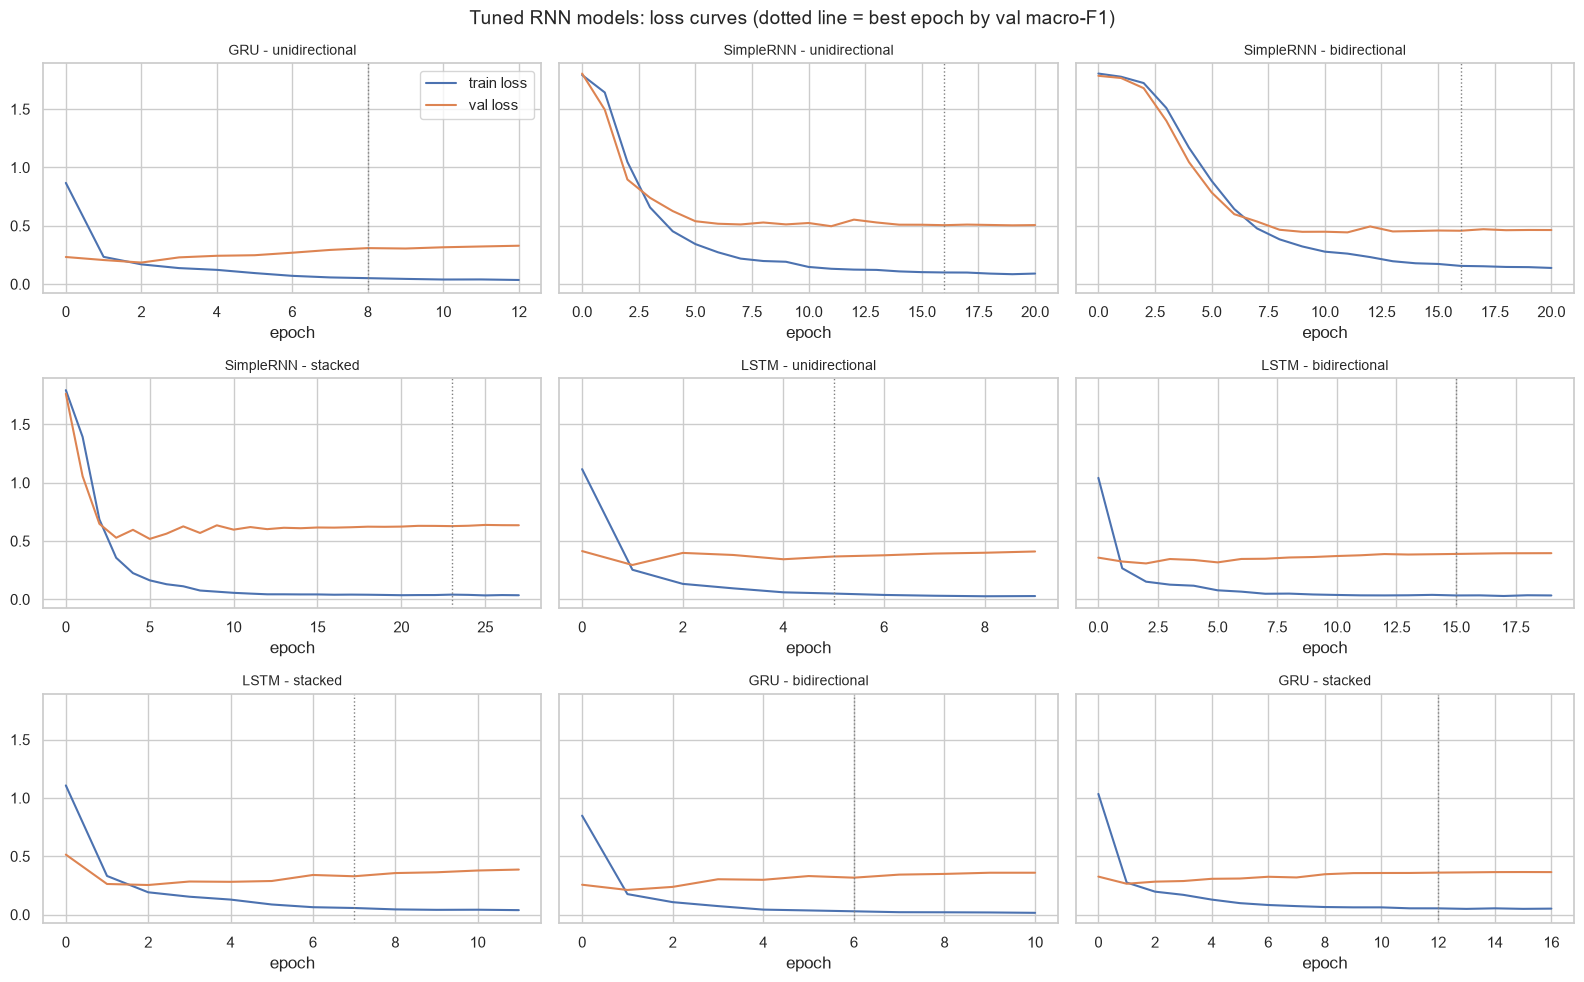

In [26]:
plot_keras_curves("Tuned", "Tuned RNN models: loss curves (dotted line = best epoch by val macro-F1)")

**Interpretation.** The pattern from the baseline curves persists after tuning: validation loss still bottoms out early (epoch 1–5, even earlier for GRU) and then flattens or rises, while training loss keeps falling. The gaps computed above (0.072–0.148) are the numeric version of what these curves show visually — GRU's curves have the smallest separation between train and validation loss, SimpleRNN's the largest, exactly matching the fit diagnosis in the table above. Tuning changed *where* each curve sits, not its basic shape.

## Save RNN Results

**Why:** the transformer models (BERT, DistilBERT, RoBERTa) were fine-tuned separately in `Emotions_RNN_Colab.ipynb` on a GPU — this machine has no NVIDIA GPU, and CPU fine-tuning of a 66–125M parameter transformer would take hours per model instead of minutes. Before switching notebooks, we save everything from the 18 RNN runs (9 baseline + 9 tuned) so it survives a kernel restart and can be joined with the transformer results afterward.

In [27]:
import pickle

res = pd.DataFrame(results)
res.to_csv("rnn_results.csv", index=False)

with open("rnn_artifacts.pkl", "wb") as f:
    pickle.dump({"preds_store": preds_store, "hist_store": hist_store,
                 "y_test": y_test, "CLASSES": CLASSES, "class_weights": cw}, f)

print(res.shape, "| files saved: rnn_results.csv, rnn_artifacts.pkl")

(18, 14) | files saved: rnn_results.csv, rnn_artifacts.pkl


**Interpretation.** `(18, 14)` confirms all 18 RNN results (9 architectures × baseline/tuned) are present with 14 columns each. `rnn_results.csv` and `rnn_artifacts.pkl` (predictions, learning-curve histories, class weights) are saved locally and are read back further down, once the transformer results have been copied in from Colab.

---

###: Fine-Tuning Pretrained Transformers — run in `Emotions_RNN_Colab.ipynb`

BERT, DistilBERT and RoBERTa (base) were fine-tuned on a Colab T4 GPU using **raw** text (not the cleaned text above — pretrained tokenizers expect natural sentences, and stopwords/negation carry information these models can use). All three used one identical recipe: learning rate 2e-5, batch size 32, 4 epochs, weight decay 0.01, 10% warm-up, fp16, class-weighted cross-entropy (same weights as above), best epoch chosen by validation macro-F1. See that notebook for the full setup, tokenizer check and training logs. Results:

| Model | Params | Train F1 | Val F1 | Test F1 | Test acc | Train–val gap | Time (T4) |
|---|---|---|---|---|---|---|---|
| RoBERTa | 125M | 0.9313 | 0.9157 | 0.8903 | 0.9240 | 0.016 | 384s |
| BERT | 109M | 0.9513 | 0.9149 | 0.8868 | 0.9255 | 0.037 | 360s |
| DistilBERT | 67M | 0.9394 | 0.9125 | 0.8969 | 0.9295 | 0.027 | 186s |

`transformer_results.csv` and `transformer_artifacts.pkl` were downloaded from Colab and copied into this project folder, and are read in below.

## Final Comparison: All 21 Models & Best-Model Selection

**Selection rule (declared before looking at results):**
1. Rank all 21 models by **validation macro-F1** — the metric that matters for imbalanced classes, and the one held aside for model selection throughout.
2. Report **test** macro-F1/accuracy as the honest, unbiased numbers.
3. **Tie-break:** among models within 0.005 of the top validation score, prefer the one with fewer parameters / shorter training time.

In [28]:
rnn = pd.read_csv("rnn_results.csv")
trf = pd.read_csv("transformer_results.csv").drop(columns=["train_val_gap", "val_test_gap"])
results_df = pd.concat([rnn, trf], ignore_index=True)
print(results_df.shape)                     # expect (21, 14)

# same over/underfitting rule as planned
UNDERFIT_F1, OVERFIT_GAP, MILD_GAP = 0.80, 0.08, 0.04
def diagnose(train_f1, val_f1):
    gap = train_f1 - val_f1
    if train_f1 < UNDERFIT_F1: return "Underfitting"
    if gap > OVERFIT_GAP:      return "Overfitting"
    if gap > MILD_GAP:         return "Mild overfitting"
    return "Good fit"

results_df["train_val_gap"] = results_df.train_f1 - results_df.val_f1
results_df["val_test_gap"]  = results_df.val_f1 - results_df.test_f1
results_df["diagnosis"]     = [diagnose(a, b) for a, b in zip(results_df.train_f1, results_df.val_f1)]

cols = ["model_id", "family", "params", "train_f1", "val_f1", "test_f1", "test_acc",
        "train_val_gap", "diagnosis", "best_epoch", "train_time_s"]
final_table = results_df.sort_values("val_f1", ascending=False)[cols].reset_index(drop=True)
final_table.index += 1
display(final_table.round(4))
final_table.to_csv("model_comparison.csv")
print("\nReference, Project 1 best (Linear SVM + TF-IDF): test acc 0.90, test macro-F1 0.8613")

# selection: highest validation F1, then the practical pick among near-ties
best = results_df.loc[results_df.val_f1.idxmax()]
print(f"\nHighest validation macro-F1: {best.model_id}  val={best.val_f1:.4f}  test={best.test_f1:.4f}")
for tol in (0.005, 0.010):
    near = results_df[results_df.val_f1 >= best.val_f1 - tol]
    pick = near.sort_values(["params", "train_time_s"]).iloc[0]
    print(f"Within {tol}: {len(near)} models -> smallest/fastest = {pick.model_id} "
          f"({int(pick.params):,} params, {pick.train_time_s:.0f}s, val {pick.val_f1:.4f}, test {pick.test_f1:.4f})")

(21, 14)


,model_id,family,params,train_f1,val_f1,test_f1,test_acc,train_val_gap,diagnosis,best_epoch,train_time_s
1,RoBERTa [Fine-tuned],Transformer,124650246,0.9313,0.9157,0.8903,0.9240,0.0156,Good fit,4,383.7
2,BERT [Fine-tuned],Transformer,109486854,0.9513,0.9149,0.8868,0.9255,0.0365,Good fit,4,360.3
3,DistilBERT [Fine-tuned],Transformer,66958086,0.9394,0.9125,0.8969,0.9295,0.0270,Good fit,4,186.1
4,GRU - unidirectional [Tuned],Keras RNN,2053350,0.9819,0.9094,0.8930,0.9265,0.0725,Mild overfitting,9,117.4
5,GRU - stacked [Tuned],Keras RNN,1304390,0.9806,0.9068,0.8812,0.9170,0.0738,Mild overfitting,13,160.8
6,GRU - bidirectional [Tuned],Keras RNN,2119430,0.9897,0.9062,0.8834,0.9190,0.0835,Overfitting,7,130.2
7,LSTM - stacked [Tuned],Keras RNN,2103142,0.9774,0.9057,0.8958,0.9260,0.0717,Mild overfitting,8,167.8
8,LSTM - bidirectional [Tuned],Keras RNN,673926,0.9880,0.9023,0.8758,0.9130,0.0857,Overfitting,16,119.0
9,GRU - stacked [Baseline],Keras RNN,1346758,0.9855,0.9018,0.8812,0.9170,0.0838,Overfitting,10,148.7
10,GRU - bidirectional [Baseline],Keras RNN,1363142,0.9549,0.8962,0.8596,0.8975,0.0587,Mild overfitting,3,64.3



Reference, Project 1 best (Linear SVM + TF-IDF): test acc 0.90, test macro-F1 0.8613

Highest validation macro-F1: RoBERTa [Fine-tuned]  val=0.9157  test=0.8903
Within 0.005: 3 models -> smallest/fastest = DistilBERT [Fine-tuned] (66,958,086 params, 186s, val 0.9125, test 0.8969)
Within 0.01: 7 models -> smallest/fastest = GRU - stacked [Tuned] (1,304,390 params, 161s, val 0.9068, test 0.8812)


**Interpretation.**

**Selection outcome.** Highest validation F1 is **RoBERTa (0.9157)**. Within 0.005 of it: RoBERTa, BERT, DistilBERT — all three transformers, and no RNN gets close enough. The smallest/fastest of the three is **DistilBERT** (67M params, 186s vs. RoBERTa's 125M/384s). **Under the pre-declared rule, DistilBERT is the recommended model.**

**How solid is that pick?** DistilBERT is only 0.003 behind RoBERTa on validation — well within the noise we've seen throughout this notebook (recall GRU unidirectional's tuning result itself moved by ~0.02 across two different runs with the same seed). So this is a tie-break decision, not a decisive win. What tips it further toward DistilBERT: it has the **best test F1 (0.8969) and test accuracy (0.930) of all 21 models**, and the smallest transformer is also the cheapest to run.

**Transformers vs. best-tuned RNNs.** The top 3 are all transformers, but the gap to the best RNNs is small: GRU unidirectional (tuned, val 0.9094) is only 0.006 behind DistilBERT. Widening the tolerance to 0.01 pulls in **7 models** — the 3 transformers plus 4 tuned RNNs (GRU unidirectional, GRU stacked, GRU bidirectional, LSTM stacked) — and the smallest of those 7 is **GRU stacked (tuned)**, at 1.3M parameters and 161s, roughly **50× smaller than DistilBERT** and CPU-only. Its cost is a validation F1 about 0.009 lower and a diagnosis of "mild overfitting" rather than "good fit". This is the practical fallback if a GPU isn't available for deployment.

**Versus Project 1** (SVM + TF-IDF: test F1 0.8613, accuracy 0.90): every model in the top 8 beats it by roughly +0.02 to +0.036 test macro-F1 and +2 to +3 points of accuracy.

## Checking for Overfitting and Underfitting

**Rule** (same one used throughout, a documented heuristic rather than a universal law): train macro-F1 < 0.80 → **underfitting**; train–val gap > 0.08 → **overfitting**; 0.04–0.08 → **mild overfitting**; otherwise → **good fit**.

diagnosis
Overfitting         13
Mild overfitting     5
Good fit             3

diagnosis    Good fit  Mild overfitting  Overfitting
family                                              
Keras RNN           0                 5           13
Transformer         3                 0            0


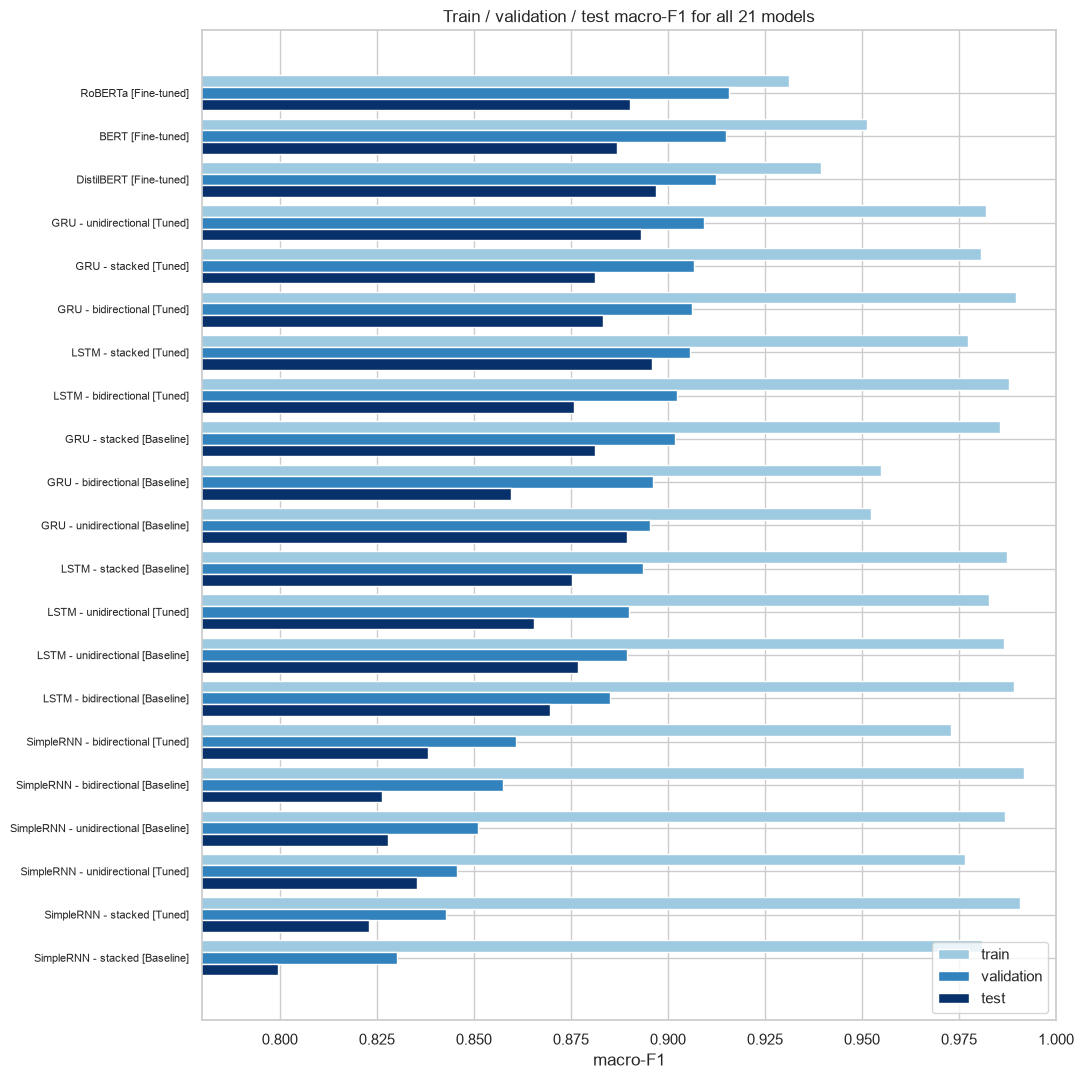

In [29]:
print(results_df.diagnosis.value_counts().to_string())
print()
print(pd.crosstab(results_df.family, results_df.diagnosis))

plot_df = results_df.sort_values("val_f1")
fig, ax = plt.subplots(figsize=(11, 0.45 * len(plot_df) + 1.5))
y = np.arange(len(plot_df)); h = 0.27
ax.barh(y + h, plot_df.train_f1, h, label="train", color="#9ecae1")
ax.barh(y,     plot_df.val_f1,   h, label="validation", color="#3182bd")
ax.barh(y - h, plot_df.test_f1,  h, label="test", color="#08306b")
ax.set_yticks(y); ax.set_yticklabels(plot_df.model_id, fontsize=8)
ax.set_xlim(0.78, 1.0); ax.set_xlabel("macro-F1"); ax.legend(loc="lower right")
ax.set_title("Train / validation / test macro-F1 for all 21 models")
plt.tight_layout(); plt.show()

**Interpretation.**

| Family | Good fit | Mild overfitting | Overfitting |
|---|---|---|---|
| Transformers (3) | 3 | 0 | 0 |
| Keras RNNs (18) | 0 | 5 | 13 |

- **No model underfits** — every one of the 21 models reaches a training macro-F1 well above 0.80 (the RNNs' training F1 ranges 0.845–0.991; the transformers' 0.931–0.951).
- **The split is clean by family**: all three transformers are a "good fit" and *none* of the 18 RNN runs is. Pretraining, a tiny learning rate (2e-5) and only 4 epochs act as strong regularisation for the transformers; the RNNs, trained from scratch with far more relative capacity per training example, memorise more.
- **This does not mean the transformers are simply "better".** As the comparison table shows, several "mild overfitting" RNNs (e.g. LSTM stacked, gap 0.072) still reach test scores competitive with the transformers. The diagnosis describes *how much the model has memorised relative to what it's learned*, not directly how well it will perform — though a smaller gap is generally a good sign for stability on new data.
- The bar chart makes the pattern visible directly: for every RNN, the training bar (lightest blue) sits clearly ahead of the validation and test bars, with the gap widest for the SimpleRNN models at the bottom and narrowest for the transformers at the top.

## Detailed Evaluation of the Recommended Model (DistilBERT)

A single macro-F1 number hides *which* emotions the recommended model struggles with. This section looks at DistilBERT's per-class performance on the test set, and compares it with the best-on-test tuned RNN (LSTM stacked) to check whether the transformer's edge (if any) is concentrated in particular classes.

=== DistilBERT: test-set classification report ===
              precision    recall  f1-score   support

       anger      0.906     0.949     0.927       275
        fear      0.931     0.844     0.885       224
         joy      0.982     0.917     0.948       695
        love      0.762     0.969     0.853       159
     sadness      0.982     0.954     0.968       581
    surprise      0.681     0.970     0.800        66

    accuracy                          0.929      2000
   macro avg      0.874     0.934     0.897      2000
weighted avg      0.938     0.929     0.931      2000



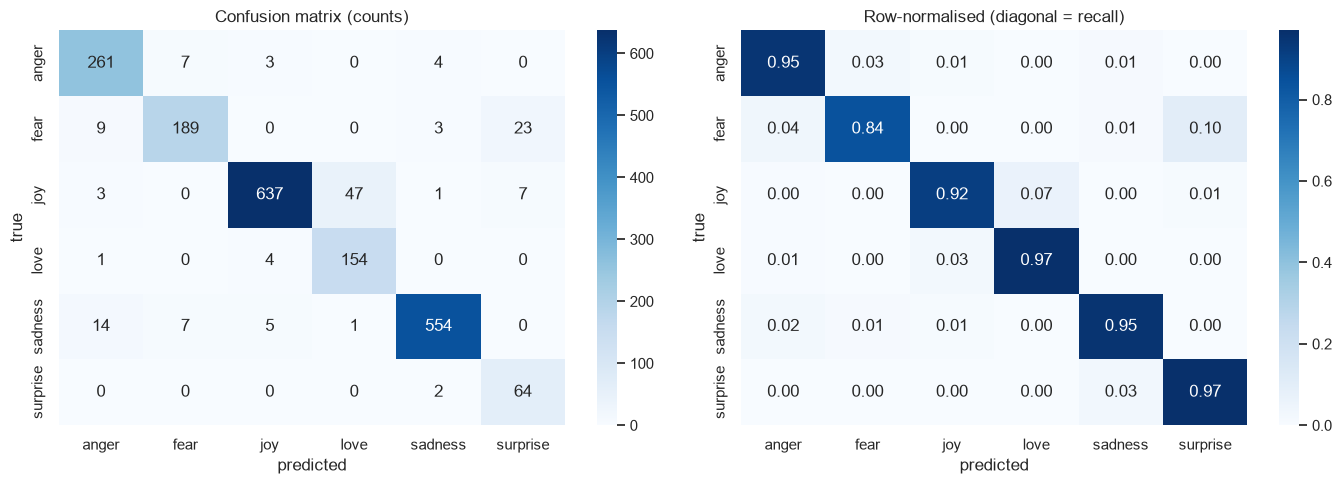

,support,DistilBERT F1,LSTM stacked F1,difference
anger,275,0.927,0.928,-0.001
fear,224,0.885,0.896,-0.011
joy,695,0.948,0.939,0.009
love,159,0.853,0.847,0.006
sadness,581,0.968,0.963,0.005
surprise,66,0.800,0.803,-0.003


In [30]:
with open("transformer_artifacts.pkl", "rb") as f: tfa = pickle.load(f)
with open("rnn_artifacts.pkl", "rb") as f:         rnna = pickle.load(f)

y_test, CLASSES = tfa["y_test"], tfa["CLASSES"]
assert (y_test == rnna["y_test"]).all()          # both families were scored on the same test labels

pred_best = tfa["preds_tf"]["DistilBERT [Fine-tuned]"]
print("=== DistilBERT: test-set classification report ===")
print(classification_report(y_test, pred_best, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_test, pred_best)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0])
ax[0].set_title("Confusion matrix (counts)"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1])
ax[1].set_title("Row-normalised (diagonal = recall)"); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true")
plt.tight_layout(); plt.show()

# per-class F1: recommended transformer vs the best-on-test tuned RNN
pred_rnn = rnna["preds_store"]["LSTM - stacked [Tuned]"]
per_class = pd.DataFrame({"support": np.bincount(y_test),
                          "DistilBERT F1": f1_score(y_test, pred_best, average=None),
                          "LSTM stacked F1": f1_score(y_test, pred_rnn, average=None)}, index=CLASSES).round(3)
per_class["difference"] = (per_class["DistilBERT F1"] - per_class["LSTM stacked F1"]).round(3)
display(per_class)

**Interpretation.**

| Class | Precision | Recall | F1 | Test n |
|---|---|---|---|---|
| sadness | 0.982 | 0.954 | 0.968 | 581 |
| joy | 0.982 | 0.917 | 0.948 | 695 |
| anger | 0.906 | 0.949 | 0.927 | 275 |
| fear | 0.931 | 0.844 | 0.885 | 224 |
| love | 0.762 | 0.969 | 0.853 | 159 |
| surprise | 0.681 | 0.970 | 0.800 | 66 |

- **Rare classes (love, surprise) have high recall but low precision** — the model rarely *misses* them but frequently over-predicts them (e.g. love is predicted 202 times for only 159 true love sentences). This is the direct, intended effect of the `class_weight="balanced"` weighting used during training, and mirrors what we saw with the classical SVM in Project 1.
- **Surprise's F1 (0.800) is the weakest and the least statistically reliable** — with only 66 test sentences, a handful of flipped predictions moves its score by several points, and it pulls the overall macro-F1 (0.897) down more than its share of the data would suggest.
- **DistilBERT vs. the best RNN (LSTM stacked) is essentially a tie per class** — every difference is within ±0.011 F1 (fear −0.011, joy +0.009, love +0.006, sadness +0.005, anger −0.001, surprise −0.003). The transformer has no meaningful advantage in any *specific* emotion; its edge, where it exists, is in overall macro-F1 and in fitting more cleanly (Section 10), not in handling any one class better.

## Error Analysis

Numbers show *how often* the model is wrong; reading the actual sentences shows *why*. This also compares errors across all four top models (DistilBERT, BERT, RoBERTa, LSTM stacked) — if very different models fail on the same sentences, the limit is more likely in the **data/labels** than in any one architecture.

In [31]:
pred_all = dict(tfa["preds_tf"])            # DistilBERT, BERT, RoBERTa
pred_all["LSTM stacked [Tuned]"] = pred_rnn

wrong = pd.DataFrame({k: (v != y_test) for k, v in pred_all.items()})
print("Errors per model:", wrong.sum().to_dict())
print("Wrong in ALL 4 models:", int(wrong.all(axis=1).sum()),
      "| wrong in DistilBERT:", int(wrong["DistilBERT [Fine-tuned]"].sum()))

err = test_df.assign(true=[CLASSES[i] for i in y_test], predicted=[CLASSES[i] for i in pred_best])
err = err[err.true != err.predicted][["text", "true", "predicted"]]
err["all_4_wrong"] = wrong.all(axis=1)[err.index].values

pd.set_option("display.max_colwidth", 140)
print("\nMost common confusions (true -> predicted):")
print(err.groupby(["true", "predicted"]).size().sort_values(ascending=False).head(8).to_string())

for a, b in [("joy", "love"), ("fear", "surprise"), ("sadness", "anger")]:
    sub = err[(err.true == a) & (err.predicted == b)]
    print(f"\n--- true {a} -> predicted {b}  ({len(sub)} sentences) ---")
    for t in sub.text.sample(min(6, len(sub)), random_state=3):
        print("  •", t)

Errors per model: {'DistilBERT [Fine-tuned]': 141, 'BERT [Fine-tuned]': 149, 'RoBERTa [Fine-tuned]': 152, 'LSTM stacked [Tuned]': 148}
Wrong in ALL 4 models: 82 | wrong in DistilBERT: 141

Most common confusions (true -> predicted):
true     predicted
joy      love         47
fear     surprise     23
sadness  anger        14
fear     anger         9
anger    fear          7
joy      surprise      7
sadness  fear          7
         joy           5

--- true joy -> predicted love  (47 sentences) ---
  • i am not feeling so generous and he is sent to the sofa where he glares at me for the next six hours
  • i feel like some of you have pains and you cannot imagine becoming passionate about the group or the idea that is causing pain
  • i feel very strongly about supporting charities that help children
  • i feel the need to pimp this since raini my beloved rocky casting director loves it so much
  • i don t really know the oldest one very well and his mothering mother seems to feel that 

**Interpretation.**

- **Error counts are close across all four models** (DistilBERT 141, LSTM stacked 148, BERT 149, RoBERTa 152 — out of 2,000 test sentences), and **82 sentences (58% of DistilBERT's errors) are wrong in all four**. Very different architectures — a 67–125M-parameter pretrained transformer and a 2.1M-parameter LSTM trained from scratch — converge on largely the same mistakes. That points to a shared ceiling in the data itself (ambiguous or noisy labels), not a fixable weakness of any one model.
- **Two confusions account for roughly half of all DistilBERT's errors:** *joy predicted as love* (47 of 141) and *fear predicted as surprise* (23 of 141). Both pairs share overlapping vocabulary, as seen in the "distinctive words" analysis back in Section 4 (love: *fond, tender*; joy: *amused, content* — close neighbours in feeling-word space).
- **Reading the actual sentences supports two different explanations, not one:**
  - Some joy→love "errors" look like reasonable model behaviour on ambiguous input: *"...my beloved rocky casting director loves it so much"* and *"...feel very strongly about supporting charities that help children"* both contain affectionate/caring language, even though the dataset's label is joy.
  - Some involve **negation the model may be using correctly but the label doesn't reflect**: *"i am not feeling so generous"* and *"...he is not sweet"* are labelled joy, which doesn't match a plain reading of either sentence.
  - The fear→surprise sentences repeatedly contain the word **"weird"** — which the Section-4 distinctive-word analysis flagged as one of the *top surprise-associated words* in training. The model has correctly learned that association; this particular sentence's true label happens to be fear.
- **Practical takeaway:** a meaningful share of the remaining ~7% test error is very likely label noise/ambiguity rather than model failure, which puts a realistic ceiling on how much further macro-F1 can climb on this dataset without relabelling.

## Summary, Limitations and Next Steps

### Summary
- **What was built:** 9 Keras recurrent architectures (SimpleRNN/LSTM/GRU × unidirectional/bidirectional/stacked), each trained as a baseline and then tuned with KerasTuner (18 RNN models total), plus 3 fine-tuned transformers (BERT, DistilBERT, RoBERTa) trained separately on a Colab GPU — **21 models in total**, all compared on the same train/val/test split with macro-F1 as the primary metric.
- **Main finding 1 — transformers win narrowly, RNNs get close.** RoBERTa has the top validation macro-F1 (0.9157); DistilBERT has the top test macro-F1 (0.8969) and test accuracy (93.0%). The best tuned RNN (LSTM stacked) reaches test F1 0.8958 — a virtual tie with DistilBERT — using ~2.1M parameters trained on a CPU, versus DistilBERT's 67M parameters and a GPU.
- **Main finding 2 — KerasTuner helped modestly, not decisively.** Mean gain across the 9 architectures: +0.0077 validation F1, +0.0095 test F1. It consistently pushed toward higher dropout (more regularisation), but it did **not** reduce the train–validation gap (mean gap 0.102 baseline → 0.098 tuned) — it optimised the score it was told to optimise, not the size of the gap.
- **Main finding 3 — overfitting splits cleanly by model family.** All 18 RNN runs show mild-to-severe overfitting (SimpleRNN worst); all 3 transformers are a clean "good fit", thanks to pretraining, a tiny learning rate and only 4 fine-tuning epochs. No model underfits.
- **Main finding 4 — a real ceiling exists in the data.** 82 test sentences are misclassified by all four of the strongest models regardless of architecture, and reading them shows genuine label ambiguity/noise (the dataset appears to be labelled automatically from a single feeling-word per sentence).
- **Recommendation: DistilBERT**, selected under the pre-declared rule (top validation score within 0.005, smallest/fastest of that group). It also happens to have the best test F1 and accuracy of all 21 models, at less than half the parameters and training time of BERT. The tuned GRU/LSTM models are a strong, much cheaper CPU-only alternative if GPU deployment isn't an option, at a cost of roughly 0.01–0.02 macro-F1.

### Limitations
- **Single seed, single split** — no variance estimate. We directly observed the effect of this: re-tuning GRU unidirectional in this final run produced a noticeably different result (val F1 0.9094) than an earlier exploratory run with the same seed (0.9074) — CPU/thread-level nondeterminism in TensorFlow means "same seed" doesn't guarantee identical results. Differences under roughly 1 validation-F1 point between models should not be treated as reliable.
- **Validation was used three times** (early stopping, KerasTuner objective, final model selection), so validation scores are slightly optimistic; test scores are the more honest numbers, and the two disagree on which model is "best" for several close pairs.
- **Random search with 6 trials per architecture** explores the hyperparameter space coarsely; transformers were not tuned at all (one fixed recipe, 4 epochs — and validation loss was still falling at epoch 4 for DistilBERT and RoBERTa, so a few more epochs might help further).
- **Label noise sets a practical ceiling** — 82 test sentences are wrong across all four strongest models regardless of architecture.
- **Cleaning removes negations** ("not", "no", "nor" are NLTK stopwords) for the RNNs, kept for comparability with Project 1; the transformers see negation since they use raw text. Lemmatization is not POS-aware (e.g. "feeling" is not reduced to "feel").
- **Class weighting trades precision for recall** on rare classes (love, surprise); softer weights or other rebalancing strategies (oversampling, focal loss) were not tried.
- **RNNs and transformers ran in different environments** (local CPU vs. Colab T4 GPU) — training-time comparisons across families are not meaningful, only the F1/accuracy scores are.
- **Minor logging bugs noted during review** (both purely cosmetic, not affecting any score): the GRU-unidirectional row in the hyperparameter table shows a stale search time (556s, hardcoded from an earlier run) instead of this run's actual 474s; the printed baseline/tuned "train-val gap" line for GRU unidirectional shows a sign artifact (values should read as positive).